# Thermoelectric Seebeck Datasets: Exploratory Study and SPB Benchmark

This notebook characterises three public Seebeck-coefficient datasets as candidate training and validation sources for symbolic-regression models of the Seebeck coefficient, benchmarked against the single parabolic band (SPB) model.

| Dataset | Source | Type | Access |
|---|---|---|---|
| BoltzTraP / Materials Project (Ricci et al., 2017) | `matminer` dataset `boltztrap_mp` | DFT, 300 K, 10¹⁸ cm⁻³ | matminer loader |
| teMatDb272 (Ryu et al., 2025) | GitHub `byungkiryu/teMatDb` | Experimental S(T) curves | GitHub API |
| ChemDataExtractor thermoelectric DB (Sierepeklis & Cole, 2022) | Figshare article 19658787 | Text-mined experimental records | Figshare API |

**Workflow**

1. Environment setup, shared utilities and a validated SPB (Pisarenko) implementation.
2. DFT dataset: schema, distributions, chemistry, symmetry, correlations, SPB benchmark, Seebeck effective mass and Fermi-surface complexity factor.
3. teMatDb272: file discovery, curve extraction, temperature coverage, bipolar-onset detection, SPB reduced Fermi level.
4. ChemDataExtractor DB: property coverage, unit normalisation, Seebeck distributions, formula parsability, publication metadata, duplicates.
5. Composition matching between DFT and experiment at three stringency levels, DFT-vs-experiment Seebeck parity, and SPB-implied carrier concentration.
6. Consolidated summary metrics and export of all derived tables and figures.

All data are downloaded at runtime; no manual upload is required. Run the cells sequentially (**Runtime → Run all**).

## 0. Environment Setup

### 0.1 Package installation
Installs `matminer` (dataset loader) and `pymatgen` (composition and symmetry analysis). The remaining dependencies are pre-installed on Google Colab.

In [1]:
%pip install -q matminer pymatgen openpyxl

Note: you may need to restart the kernel to use updated packages.


### 0.2 Imports and display settings

In [2]:
import io
import os
import re
import sys
import json
import zipfile
import warnings
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from scipy import integrate, interpolate, special, stats
from IPython.display import display, Markdown

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

IN_COLAB = "google.colab" in sys.modules

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "figure.figsize": (8, 5),
                     "axes.titleweight": "bold"})

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | Colab: {IN_COLAB}")

Python 3.11.9 | pandas 2.3.3 | numpy 2.4.6 | Colab: False


### 0.3 Configuration
All tunable parameters are centralised here. `COLUMN_OVERRIDES` allows manual column assignment if automatic schema detection selects the wrong column for a dataset.

In [3]:
BASE_DIR = Path("/content") if IN_COLAB else Path.cwd()

CONFIG = {
    "data_dir": BASE_DIR / "data",
    "output_dir": BASE_DIR / "outputs",
    "tematdb_repo": "byungkiryu/teMatDb",
    "tematdb_preferred_dir": "teMatDb_publication",
    "tematdb_max_files": 40,
    "tematdb_max_file_mb": 150,
    "figshare_article_id": 19658787,
    "T_ref": 300.0,
    "T_window": 25.0,
    "dft_doping_cm3": 1e18,
    "scattering_r": -0.5,
    "composition_tolerance": 0.05,
    "min_points_per_curve": 5,
    "S_plausible_max_uVK": 2000.0,
    "compute_symmetry": True,
    "random_state": 0,
}

COLUMN_OVERRIDES = {
    "tematdb": {"sample_id": None, "temperature": None, "seebeck": None,
                "group": None, "basemat": None, "composition": None},
    "cde": {"name": None, "specifier": None, "model": None, "value": None, "unit": None,
            "T_value": None, "T_unit": None, "doi": None, "date": None},
}

for key in ("data_dir", "output_dir"):
    CONFIG[key].mkdir(parents=True, exist_ok=True)
(CONFIG["output_dir"] / "figures").mkdir(exist_ok=True)
(CONFIG["output_dir"] / "tables").mkdir(exist_ok=True)

RNG = np.random.default_rng(CONFIG["random_state"])
SUMMARY = {}

### 0.4 Shared utilities
- `SESSION` / `fetch_bytes`: HTTP client with automatic retries and on-disk caching.
- `get_github_token`: optional GitHub token from Colab *Secrets* (`GITHUB_TOKEN`) to avoid API rate limits.
- `find_col`: regex-based column resolution with manual override support.
- `first_number`: robust numeric extraction from text fields.
- `missingness_report`: per-column type, missing fraction and cardinality.
- `save_fig` / `save_table`: persist figures and tables to the output directory.

In [4]:
def make_session():
    session = requests.Session()
    retry = Retry(total=4, backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504),
                  allowed_methods=("GET",))
    session.mount("https://", HTTPAdapter(max_retries=retry))
    session.headers["User-Agent"] = "thermoelectric-dataset-study/2.0"
    return session


SESSION = make_session()


def get_github_token():
    token = os.environ.get("GITHUB_TOKEN")
    if token:
        return token
    try:
        from google.colab import userdata
        return userdata.get("GITHUB_TOKEN")
    except Exception:
        return None


def fetch_bytes(url, cache_name=None, headers=None, timeout=180):
    path = CONFIG["data_dir"] / cache_name if cache_name else None
    if path is not None and path.exists() and path.stat().st_size > 0:
        return path.read_bytes()
    response = SESSION.get(url, headers=headers, timeout=timeout)
    response.raise_for_status()
    if path is not None:
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(response.content)
    return response.content


def find_col(df, pattern, exclude=None, override=None):
    if df is None:
        return None
    if override is not None and override in df.columns:
        return override
    for col in df.columns:
        name = str(col).strip()
        if re.search(pattern, name, re.I) and not (exclude and re.search(exclude, name, re.I)):
            return col
    return None


NUM_RE = re.compile(r"[-+]?(?:\d+\.\d*|\.\d+|\d+)(?:[eE][-+]?\d+)?")


def first_number(x):
    if isinstance(x, (bool, np.bool_)):
        return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)):
        return float(x) if np.isfinite(x) else np.nan
    if not isinstance(x, str):
        return np.nan
    match = NUM_RE.search(x.replace("−", "-"))
    return float(match.group()) if match else np.nan


def safe_nunique(series):
    try:
        return series.nunique()
    except TypeError:
        return series.astype(str).nunique()


def missingness_report(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (100 * df.isna().mean()).round(2),
        "n_unique": [safe_nunique(df[c]) for c in df.columns],
    }).sort_values("pct_missing", ascending=False)


def save_fig(fig, name):
    fig.savefig(CONFIG["output_dir"] / "figures" / f"{name}.png", bbox_inches="tight")


def save_table(df, name):
    if df is not None and len(df):
        df.to_csv(CONFIG["output_dir"] / "tables" / f"{name}.csv", index=False)


def header(text):
    display(Markdown(f"**{text}**"))

### 0.5 Single parabolic band (SPB) model

The SPB model with energy-independent scattering exponent $r$ (acoustic-phonon scattering: $r=-1/2$) gives

$$S = \frac{k_B}{e}\left[\frac{(r+5/2)\,F_{r+3/2}(\eta)}{(r+3/2)\,F_{r+1/2}(\eta)} - \eta\right],\qquad
n = 4\pi\left(\frac{2 m^{*} k_B T}{h^{2}}\right)^{3/2} F_{1/2}(\eta),$$

where $F_j(\eta)=\int_0^\infty x^j/(1+e^{x-\eta})\,dx$ is the Fermi–Dirac integral and $\eta$ the reduced chemical potential. The `SPBModel` class tabulates both relations on a dense $\eta$ grid and inverts them by interpolation, providing:

| Method | Output |
|---|---|
| `seebeck_from_n(n, m, T)` | Pisarenko prediction of \|S\| (µV/K) |
| `eta_from_seebeck(S)` | reduced Fermi level from measured \|S\| |
| `seebeck_mass(S, n, T)` | Seebeck (density-of-states) effective mass $m_S^*/m_e$ |
| `carrier_conc(S, m, T)` | carrier concentration (cm⁻³) reproducing \|S\| for a given $m^*$ |
| `reduced_density(S, T)` | $n/(m^*/m_e)^{3/2}$ (cm⁻³), obtainable without Hall data |
| `degenerate_slope(m, n)` | Mott-limit $dS/dT$ (µV/K²) |

In [5]:
KB = 1.380649e-23
QE = 1.602176634e-19
H = 6.62607015e-34
ME = 9.1093837015e-31
KB_E_UV = KB / QE * 1e6


def fermi_integral(j, eta):
    eta = np.atleast_1d(np.asarray(eta, dtype=float))
    if j == 0:
        return np.logaddexp(0.0, eta)
    out = np.empty_like(eta)
    for i, e in enumerate(eta):
        upper = max(e, 0.0) + 60.0
        pts = [e] if e > 0 else None
        out[i] = integrate.quad(lambda x: x ** j * special.expit(e - x), 0.0, upper,
                                points=pts, limit=200)[0]
    return out


class SPBModel:
    def __init__(self, r=-0.5, eta_min=-25.0, eta_max=80.0, n_grid=2000):
        self.r = r
        self.eta = np.linspace(eta_min, eta_max, n_grid)
        f_hi = fermi_integral(r + 1.5, self.eta)
        f_lo = fermi_integral(r + 0.5, self.eta)
        self.S = KB_E_UV * ((r + 2.5) * f_hi / ((r + 1.5) * f_lo) - self.eta)
        self.log_F_half = np.log(fermi_integral(0.5, self.eta))
        self._eta_of_S = interpolate.interp1d(self.S[::-1], self.eta[::-1], bounds_error=False, fill_value=np.nan)
        self._eta_of_logF = interpolate.interp1d(self.log_F_half, self.eta, bounds_error=False, fill_value=np.nan)
        self._logF_of_eta = interpolate.interp1d(self.eta, self.log_F_half, bounds_error=False, fill_value=np.nan)
        self._S_of_eta = interpolate.interp1d(self.eta, self.S, bounds_error=False, fill_value=np.nan)
        self.S_range = (self.S.min(), self.S.max())

    @staticmethod
    def effective_dos(m, T):
        m = np.asarray(m, dtype=float)
        return 4 * np.pi * (2 * m * ME * KB * T / H ** 2) ** 1.5 * 1e-6

    def eta_from_seebeck(self, S_abs):
        return self._eta_of_S(np.abs(np.asarray(S_abs, dtype=float)))

    def seebeck_from_n(self, n_cm3, m, T):
        with np.errstate(divide="ignore", invalid="ignore"):
            eta = self._eta_of_logF(np.log(np.asarray(n_cm3, float) / self.effective_dos(m, T)))
        return self._S_of_eta(eta)

    def seebeck_mass(self, S_abs, n_cm3, T):
        eta = self.eta_from_seebeck(S_abs)
        F = np.exp(self._logF_of_eta(eta))
        n_m3 = np.asarray(n_cm3, float) * 1e6
        return (n_m3 / (4 * np.pi * F)) ** (2 / 3) * H ** 2 / (2 * KB * T) / ME

    def carrier_conc(self, S_abs, m, T):
        eta = self.eta_from_seebeck(S_abs)
        return self.effective_dos(m, T) * np.exp(self._logF_of_eta(eta))

    def reduced_density(self, S_abs, T):
        return self.carrier_conc(S_abs, 1.0, T)

    @staticmethod
    def degenerate_slope(m, n_cm3):
        n_m3 = np.asarray(n_cm3, float) * 1e6
        return 8 * np.pi ** 2 * KB ** 2 / (3 * QE * H ** 2) * np.asarray(m) * ME * (np.pi / (3 * n_m3)) ** (2 / 3) * 1e6


spb = SPBModel(r=CONFIG["scattering_r"])
print(f"SPB tabulated: |S| range {spb.S_range[0]:.2f} - {spb.S_range[1]:.0f} µV/K (r = {spb.r})")

SPB tabulated: |S| range 3.54 - 2327 µV/K (r = -0.5)


### 0.6 SPB validation
The implementation is verified against (i) the analytic non-degenerate limit $S=\frac{k_B}{e}(2-\eta)$ with $\eta=\ln(n/N_c)$, (ii) the degenerate Mott limit, and (iii) round-trip consistency of the forward and inverse relations. The Pisarenko curves for representative effective masses are plotted for reference.

,check,numerical,reference
0,"Non-degenerate limit (n=1e16, m*=1, 300 K)",846.9,846.9
1,"Degenerate limit (n=1e21, m*=0.5, 300 K)",10.06,10.05
2,Round-trip n -> S -> n (max rel. error),8.882e-16,0
3,Round-trip m* -> S -> m* (max rel. error),2.331e-15,0


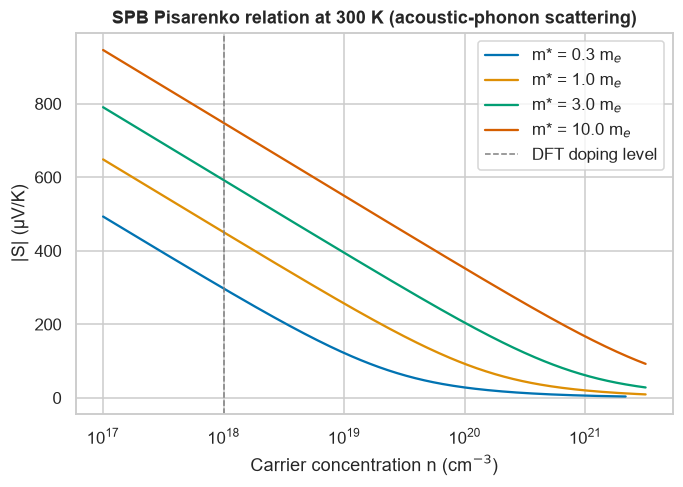

In [6]:
T0 = 300.0
n_low = 1e16
S_num = float(spb.seebeck_from_n(n_low, 1.0, T0))
S_ana = KB_E_UV * (2 - np.log(n_low / (spb.effective_dos(1.0, T0) * np.sqrt(np.pi) / 2)))

n_deg, m_deg, T_deg = 1e21, 0.5, 300.0
S_deg_num = float(spb.seebeck_from_n(n_deg, m_deg, T_deg))
S_deg_ana = float(spb.degenerate_slope(m_deg, n_deg) * T_deg)

n_grid = np.logspace(17, 21, 9)
S_fwd = spb.seebeck_from_n(n_grid, 1.5, T0)
n_back = spb.carrier_conc(S_fwd, 1.5, T0)
m_back = spb.seebeck_mass(S_fwd, n_grid, T0)

validation = pd.DataFrame({
    "check": ["Non-degenerate limit (n=1e16, m*=1, 300 K)", "Degenerate limit (n=1e21, m*=0.5, 300 K)",
              "Round-trip n -> S -> n (max rel. error)", "Round-trip m* -> S -> m* (max rel. error)"],
    "numerical": [S_num, S_deg_num, np.max(np.abs(n_back / n_grid - 1)), np.max(np.abs(m_back / 1.5 - 1))],
    "reference": [S_ana, S_deg_ana, 0.0, 0.0],
})
display(validation)

fig, ax = plt.subplots(figsize=(7, 4.5))
n_plot = np.logspace(17, 21.5, 300)
for m in (0.3, 1.0, 3.0, 10.0):
    ax.plot(n_plot, spb.seebeck_from_n(n_plot, m, T0), label=f"m* = {m} m$_e$")
ax.axvline(CONFIG["dft_doping_cm3"], ls="--", c="grey", lw=1, label="DFT doping level")
ax.set(xscale="log", xlabel="Carrier concentration n (cm$^{-3}$)", ylabel="|S| (µV/K)",
       title="SPB Pisarenko relation at 300 K (acoustic-phonon scattering)")
ax.legend()
save_fig(fig, "00_pisarenko_reference")
plt.show()

## 1. DFT / BoltzTraP Dataset (Ricci et al., 2017)

### 1.1 Loading
Loads `boltztrap_mp` through `matminer` (cached after the first download) and prints the official dataset description.

In [7]:
from matminer.datasets import load_dataset, get_all_dataset_info

df_dft_raw = load_dataset("boltztrap_mp", data_home=str(CONFIG["data_dir"] / "matminer"))
print(get_all_dataset_info("boltztrap_mp"))
print(f"Shape: {df_dft_raw.shape}")
display(df_dft_raw.drop(columns=[c for c in ["structure"] if c in df_dft_raw]).head())

Making dataset storage folder at C:\Users\Ekta Jain\Downloads\nb_run\repos\seebeck-spb-symbolic-regression\data_audits\data\matminer


Fetching boltztrap_mp.json.gz from https://ndownloader.figshare.com/files/13297511 to C:\Users\Ekta Jain\Downloads\nb_run\repos\seebeck-spb-symbolic-regression\data_audits\data\matminer\boltztrap_mp.json.gz


Fetching https://ndownloader.figshare.com/files/13297511 in MB:   0%|          | 0.0/14.020266999999999 [00:00<?, ?MB/s]

Fetching https://ndownloader.figshare.com/files/13297511 in MB: 14.020608MB [00:00, 475.42MB/s]                         

Dataset: boltztrap_mp
Description: Effective mass and thermoelectric properties of 8924 compounds in The  Materials Project database that are calculated by the BoltzTraP software package run on the GGA-PBE or GGA+U density functional theory calculation results. The properties are reported at the temperature of 300 Kelvin and the carrier concentration of 1e18 1/cm3.
Columns:
	formula: Chemical formula of the entry
	m_n: n-type/conduction band effective mass. Units: m_e where m_e is the mass of an electron; i.e. m_n is a unitless ratio
	m_p: p-type/valence band effective mass.
	mpid: Materials Project identifier
	pf_n: n-type thermoelectric power factor in uW/cm2.K where uW is microwatts and a constant relaxation time of 1e-14 assumed.
	pf_p: p-type power factor in uW/cm2.K
	s_n: n-type Seebeck coefficient in micro Volts per Kelvin
	s_p: p-type Seebeck coefficient in micro Volts per Kelvin
	structure: pymatgen Structure object describing the crystal structure of the material
Num Entries:

,mpid,pf_n,pf_p,s_n,s_p,formula,m_n,m_p
0,mp-10070,0.865,0.0125,-421,760,BaAg(PO3)3,0.578,72.8
1,mp-10086,1.05,0.644,-393,567,YSF,0.541,4.02
2,mp-10096,0.977,0.42,-305,471,Na3Sr3GaP4,0.27,1.02
3,mp-10103,0.889,0.0257,-416,871,YbLiAlF6,0.548,20.3
4,mp-10155,0.719,1.57,-496,510,P2Ir,1.16,0.667


### 1.2 Schema, missingness and single-point verification
Reports column types and missing values, and tests whether the matminer slice contains any temperature or doping dimension. The original Ricci et al. deposit spans 10¹⁶–10²⁰ cm⁻³ and 100–1300 K; this slice is expected to be fixed at 300 K and 10¹⁸ cm⁻³.

In [8]:
display(missingness_report(df_dft_raw.drop(columns=[c for c in ["structure"] if c in df_dft_raw])))

condition_cols = [c for c in df_dft_raw.columns
                  if re.search(r"^t$|temp|doping|carrier|conc|^n$", str(c), re.I)]
single_point = len(condition_cols) == 0
print(f"Condition-like columns: {condition_cols or 'none'}")
print(f"Single-point dataset confirmed (300 K, 1e18 cm^-3): {single_point}")
SUMMARY["DFT: single-point (300 K, 1e18 cm^-3)"] = single_point

,dtype,n_missing,pct_missing,n_unique
mpid,object,0,0,8924
pf_n,float64,0,0,1845
pf_p,float64,0,0,2138
s_n,float64,0,0,849
s_p,float64,0,0,748
formula,object,0,0,7380
m_n,float64,0,0,2815
m_p,float64,0,0,2630


Condition-like columns: none
Single-point dataset confirmed (300 K, 1e18 cm^-3): True


### 1.3 Cleaning and sign consistency
Coerces transport columns to numeric, and checks the physically expected sign convention (n-type $S<0$, p-type $S>0$) and positivity of effective masses and power factors. Rows violating these constraints are flagged, not removed.

In [9]:
df_dft = df_dft_raw.copy()
TRANSPORT_COLS = [c for c in ["s_n", "s_p", "pf_n", "pf_p", "m_n", "m_p"] if c in df_dft]
df_dft[TRANSPORT_COLS] = df_dft[TRANSPORT_COLS].apply(pd.to_numeric, errors="coerce")

checks = {
    "s_n < 0": (df_dft["s_n"] < 0).mean(),
    "s_p > 0": (df_dft["s_p"] > 0).mean(),
    "m_n > 0": (df_dft["m_n"] > 0).mean(),
    "m_p > 0": (df_dft["m_p"] > 0).mean(),
    "pf_n >= 0": (df_dft["pf_n"] >= 0).mean(),
    "pf_p >= 0": (df_dft["pf_p"] >= 0).mean(),
}
display(pd.Series(checks, name="fraction satisfied").to_frame())

df_dft["sign_anomaly"] = ~((df_dft["s_n"] <= 0) & (df_dft["s_p"] >= 0))
df_dft["abs_s_n"] = df_dft["s_n"].abs()
df_dft["abs_s_p"] = df_dft["s_p"].abs()
for col in ["pf_n", "pf_p", "m_n", "m_p"]:
    df_dft[f"log10_{col}"] = np.log10(df_dft[col].where(df_dft[col] > 0))

print(f"Rows with sign anomalies: {df_dft['sign_anomaly'].sum()} / {len(df_dft)}")
display(df_dft[TRANSPORT_COLS].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)

,fraction satisfied
s_n < 0,0.9923
s_p > 0,0.9885
m_n > 0,1
m_p > 0,1
pf_n >= 0,1
pf_p >= 0,1


Rows with sign anomalies: 172 / 8924


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
s_n,"8,924",-545.2,163.6,"-1,120",-868.8,-781,-676,-549,-418,-322,-63.84,655
s_p,"8,924",676.1,142.9,-691,-29.78,482,636,703,756,821,865,"1,090"
pf_n,"8,924",0.6663,0.4669,8.93e-07,0.003325,0.02402,0.267,0.71,0.936,1.39,2.053,6.71
pf_p,"8,924",0.299,0.4349,1.54e-05,0.002112,0.01132,0.0641,0.166,0.373,1.01,2.058,7.29
m_n,"8,924",1.483e+04,7.967e+05,0.0159,0.155,0.3202,0.5768,1.79,13.8,457.6,1.333e+04,6.65e+07
m_p,"8,924",2.023e+04,1.236e+06,0.016,0.3402,1.02,3.71,11,41.73,559.9,1.198e+04,1.14e+08


### 1.4 Distributions of transport properties
Histograms of |S|, log₁₀ PF and log₁₀ m* for n- and p-type doping. Effective masses and power factors span several orders of magnitude and are therefore shown on logarithmic axes.

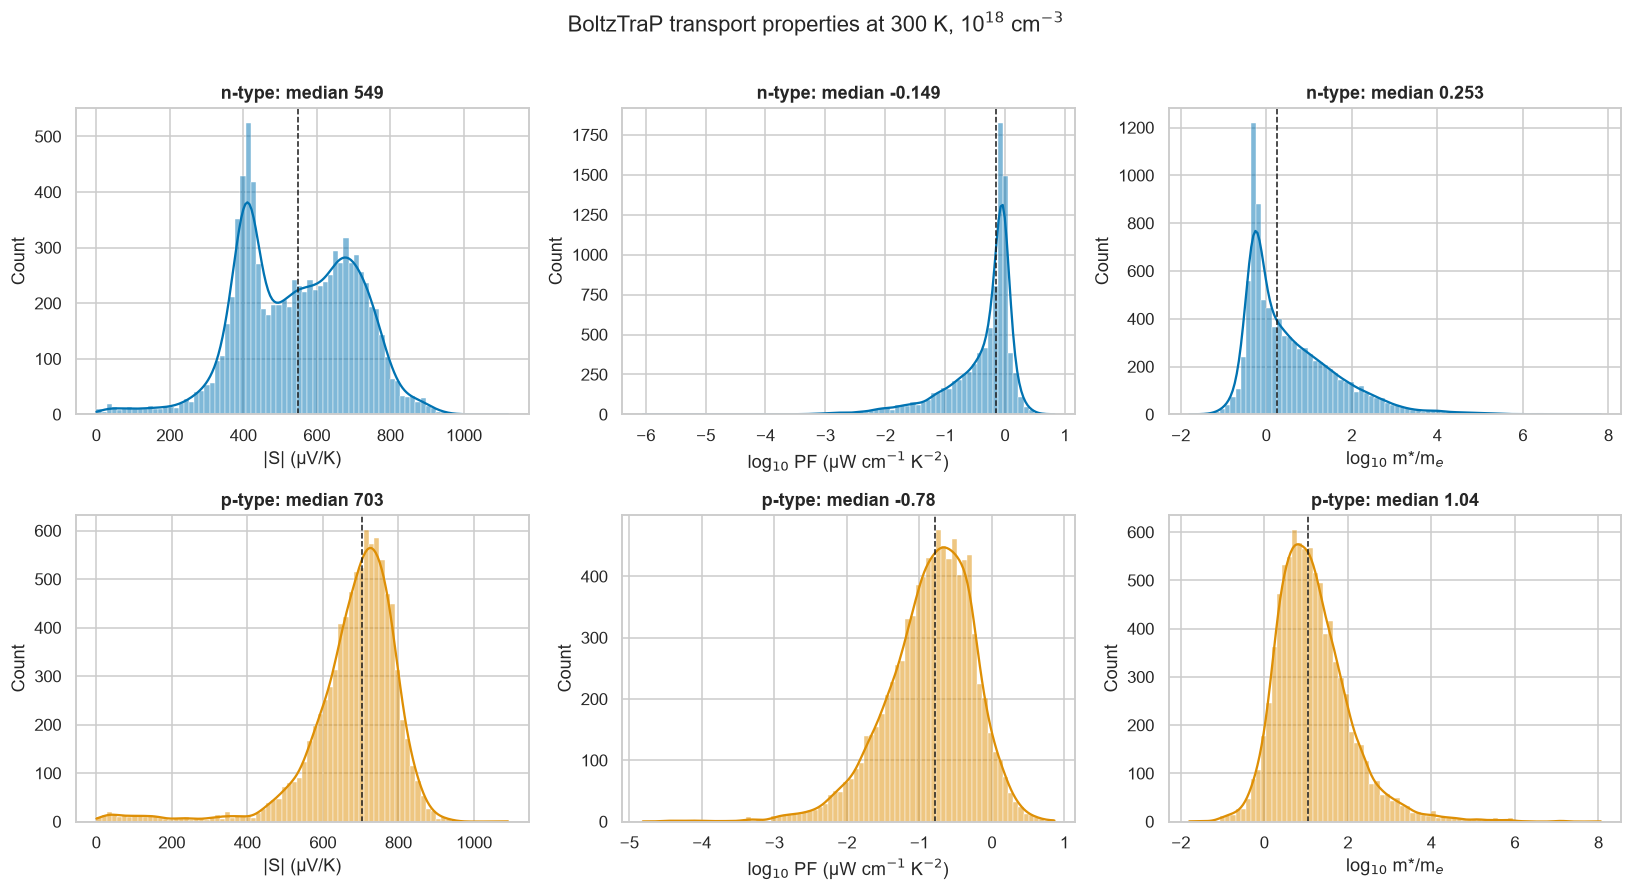

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
panels = [("abs_s", "|S| (µV/K)"), ("log10_pf", "log$_{10}$ PF (µW cm$^{-1}$ K$^{-2}$)"),
          ("log10_m", "log$_{10}$ m*/m$_e$")]
for row, carrier in enumerate(["n", "p"]):
    for col, (prefix, label) in enumerate(panels):
        ax = axes[row, col]
        data = df_dft[f"{prefix}_{carrier}"].replace([np.inf, -np.inf], np.nan).dropna()
        sns.histplot(data, bins=80, ax=ax, color=f"C{row}", kde=True)
        ax.axvline(data.median(), c="k", ls="--", lw=1)
        ax.set(xlabel=label, title=f"{carrier}-type: median {data.median():.3g}")
fig.suptitle("BoltzTraP transport properties at 300 K, 10$^{18}$ cm$^{-3}$", y=1.01)
fig.tight_layout()
save_fig(fig, "01_dft_distributions")
plt.show()

### 1.5 Composition features
Each formula is parsed with `pymatgen` to derive the reduced formula, chemical system, number of elements, anion (most electronegative element), chemical class and electronegativity spread $\Delta\chi$ (an ionicity proxy).

In [11]:
from pymatgen.core import Composition

ANION_CLASS = {"O": "oxide", "S": "chalcogenide", "Se": "chalcogenide", "Te": "chalcogenide",
               "N": "pnictide", "P": "pnictide", "As": "pnictide", "Sb": "pnictide",
               "F": "halide", "Cl": "halide", "Br": "halide", "I": "halide", "H": "hydride"}


@lru_cache(maxsize=None)
def composition_features(formula):
    empty = {"reduced_formula": None, "chemsys": None, "n_elements": np.nan,
             "anion": None, "chem_class": None, "delta_chi": np.nan}
    if not isinstance(formula, str) or not formula.strip():
        return empty
    try:
        comp = Composition(formula)
    except Exception:
        return empty
    elements = [el for el in comp.elements]
    chis = {el.symbol: (el.X if el.X == el.X else np.nan) for el in elements}
    valid = {k: v for k, v in chis.items() if np.isfinite(v)}
    anion = max(valid, key=valid.get) if valid else None
    if len(elements) == 1:
        chem_class = "elemental"
    else:
        chem_class = ANION_CLASS.get(anion, "intermetallic/other")
    return {"reduced_formula": comp.reduced_formula, "chemsys": comp.chemical_system,
            "n_elements": len(elements), "anion": anion, "chem_class": chem_class,
            "delta_chi": (max(valid.values()) - min(valid.values())) if len(valid) > 1 else 0.0}


feat = pd.DataFrame([composition_features(f) for f in df_dft["formula"]], index=df_dft.index)
df_dft = pd.concat([df_dft.drop(columns=[c for c in feat.columns if c in df_dft]), feat], axis=1)

print(f"Formulas parsed: {df_dft['reduced_formula'].notna().mean():.1%}")
print(f"Unique reduced formulas: {df_dft['reduced_formula'].nunique()} across {len(df_dft)} entries")
SUMMARY["DFT: entries"] = len(df_dft)
SUMMARY["DFT: unique reduced formulas"] = df_dft["reduced_formula"].nunique()

frac_pattern = df_dft["formula"].astype(str).str.contains(r"\d+\.\d+")
print(f"Formulas with fractional stoichiometry (doped/alloyed notation): {frac_pattern.sum()}")

display(pd.concat([df_dft["chem_class"].value_counts().rename("count"),
                   df_dft["chem_class"].value_counts(normalize=True).mul(100).round(1).rename("%")], axis=1))
display(df_dft["n_elements"].value_counts().sort_index().rename("count").to_frame().T)

Formulas parsed: 100.0%
Unique reduced formulas: 7380 across 8924 entries
Formulas with fractional stoichiometry (doped/alloyed notation): 0


,count,%
chem_class,,
oxide,5407,60.6
halide,1984,22.2
chalcogenide,857,9.6
pnictide,470,5.3
intermetallic/other,96,1.1
hydride,77,0.9
elemental,33,0.4


n_elements,1,2,3,4,5,6,7
count,33,782,4208,2837,881,167,16


### 1.6 Crystal symmetry
Assigns a crystal system to each structure using `SpacegroupAnalyzer` (tolerance 0.1 Å). Disable with `CONFIG["compute_symmetry"] = False` to save time.

In [12]:
df_dft["crystal_system"] = None
if CONFIG["compute_symmetry"] and "structure" in df_dft:
    from pymatgen.symmetry.analyzer import SpacegroupAnalyzer

    def crystal_system(structure):
        try:
            return SpacegroupAnalyzer(structure, symprec=0.1).get_crystal_system()
        except Exception:
            return None

    df_dft["crystal_system"] = [crystal_system(s) for s in tqdm(df_dft["structure"], desc="Symmetry")]
    display(df_dft["crystal_system"].value_counts().rename("count").to_frame().T)

Symmetry:   0%|          | 0/8924 [00:00<?, ?it/s]

crystal_system,monoclinic,orthorhombic,triclinic,tetragonal,trigonal,cubic,hexagonal
count,3041,2207,1018,864,860,552,382


### 1.7 Seebeck coefficient by chemistry and symmetry
Compares the |S| distributions across chemical classes, number of constituent elements and crystal systems for both carrier types. Kruskal–Wallis tests assess whether group medians differ significantly.

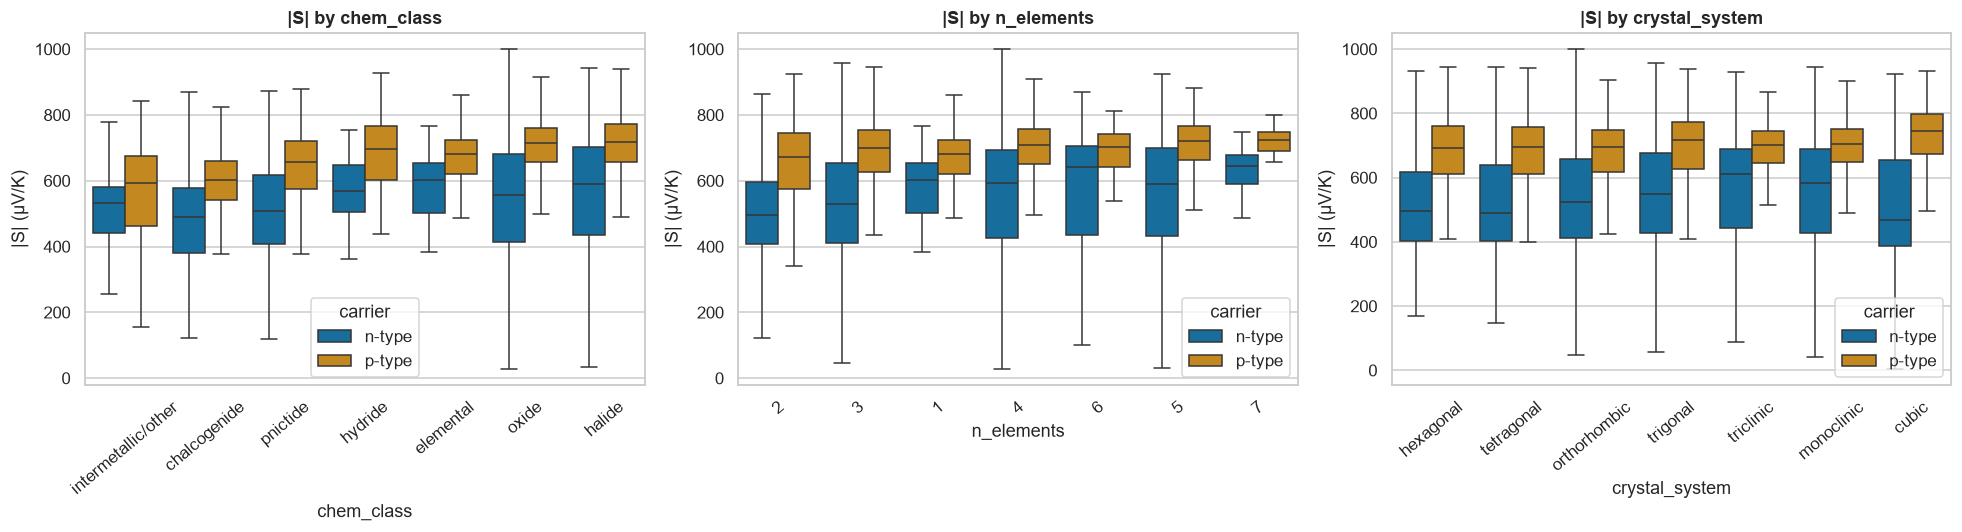

,grouping,carrier,H,p_value
0,chem_class,n-type,249.7,4.788e-51
1,chem_class,p-type,"1,065",9.155e-227
2,n_elements,n-type,208.6,2.777e-42
3,n_elements,p-type,114.9,1.956e-22
4,crystal_system,n-type,216.9,4.752e-44
5,crystal_system,p-type,142.7,2.762e-28


In [13]:
long_S = df_dft.melt(id_vars=["chem_class", "n_elements", "crystal_system"],
                     value_vars=["abs_s_n", "abs_s_p"], var_name="carrier", value_name="|S| (µV/K)")
long_S["carrier"] = long_S["carrier"].map({"abs_s_n": "n-type", "abs_s_p": "p-type"})

groupings = ["chem_class", "n_elements"] + (["crystal_system"] if df_dft["crystal_system"].notna().any() else [])
fig, axes = plt.subplots(1, len(groupings), figsize=(6 * len(groupings), 5))
axes = np.atleast_1d(axes)
kw_rows = []
for ax, g in zip(axes, groupings):
    sub = long_S.dropna(subset=[g])
    order = sub.groupby(g)["|S| (µV/K)"].median().sort_values().index
    sns.boxplot(data=sub, x=g, y="|S| (µV/K)", hue="carrier", order=order, ax=ax,
                showfliers=False)
    ax.tick_params(axis="x", rotation=40)
    ax.set_title(f"|S| by {g}")
    for carrier, cs in sub.groupby("carrier"):
        samples = [v["|S| (µV/K)"].dropna().values for _, v in cs.groupby(g) if len(v) >= 5]
        if len(samples) > 1:
            H_stat, p_val = stats.kruskal(*samples)
            kw_rows.append({"grouping": g, "carrier": carrier, "H": H_stat, "p_value": p_val})
fig.tight_layout()
save_fig(fig, "01_dft_seebeck_by_group")
plt.show()
display(pd.DataFrame(kw_rows))

### 1.8 Correlation structure
Spearman rank correlations between transport properties and composition descriptors. Rank correlation is used because the variables are strongly skewed and relationships are monotonic rather than linear.

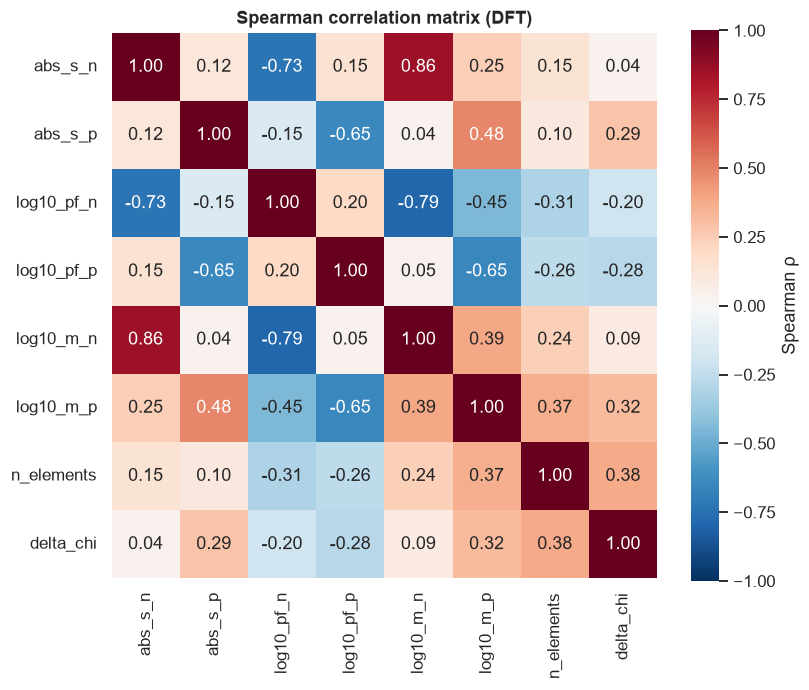

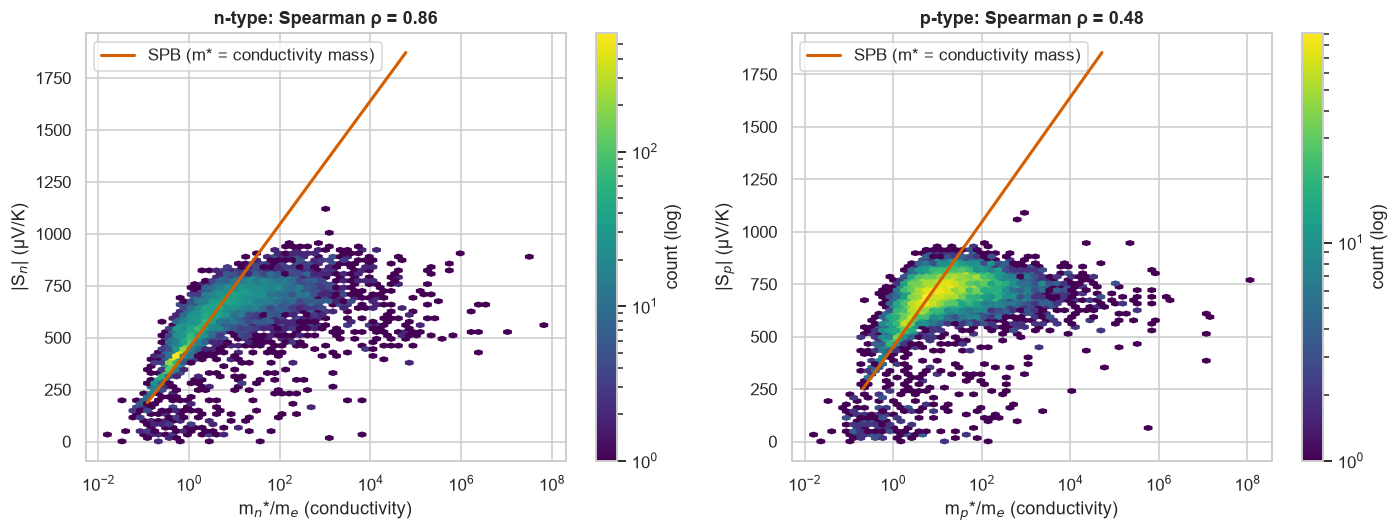

In [14]:
corr_cols = ["abs_s_n", "abs_s_p", "log10_pf_n", "log10_pf_p", "log10_m_n", "log10_m_p",
             "n_elements", "delta_chi"]
corr = df_dft[corr_cols].replace([np.inf, -np.inf], np.nan).corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman ρ"})
ax.set_title("Spearman correlation matrix (DFT)")
save_fig(fig, "01_dft_correlations")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, c in zip(axes, ["n", "p"]):
    sub = df_dft[[f"m_{c}", f"abs_s_{c}"]].replace([np.inf, -np.inf], np.nan).dropna()
    sub = sub[sub[f"m_{c}"] > 0]
    hb = ax.hexbin(sub[f"m_{c}"], sub[f"abs_s_{c}"], xscale="log", gridsize=60, bins="log", cmap="viridis", mincnt=1)
    m_line = np.logspace(np.log10(sub[f"m_{c}"].quantile(0.005)), np.log10(sub[f"m_{c}"].quantile(0.995)), 200)
    ax.plot(m_line, spb.seebeck_from_n(CONFIG["dft_doping_cm3"], m_line, CONFIG["T_ref"]), c="r", lw=2,
            label="SPB (m* = conductivity mass)")
    rho = stats.spearmanr(sub[f"m_{c}"], sub[f"abs_s_{c}"]).statistic
    ax.set(xlabel=f"m$_{c}$*/m$_e$ (conductivity)", ylabel=f"|S$_{c}$| (µV/K)", title=f"{c}-type: Spearman ρ = {rho:.2f}")
    ax.legend()
    fig.colorbar(hb, ax=ax, label="count (log)")
fig.tight_layout()
save_fig(fig, "01_dft_mass_vs_seebeck")
plt.show()

### 1.9 SPB benchmark on DFT data
For every compound the SPB model is evaluated at the DFT conditions (300 K, 10¹⁸ cm⁻³) using the BoltzTraP conductivity effective mass, and compared with the BoltzTraP Seebeck coefficient. Deviations quantify how far real band structures depart from a single isotropic parabolic band: multi-valley degeneracy and anisotropy raise the density-of-states mass above the conductivity mass, so SPB with $m_c^*$ systematically under-predicts |S|.

Metrics reported: Spearman ρ, median log₁₀ ratio (bias), median absolute percentage error (MdAPE) and the fraction of compounds within ±20 %.

,n,spearman_rho,median_log10_ratio,MdAPE_%,within_20%,SPB_underpredicts
carrier,,,,,,
n,8917,0.8559,-0.02199,10.9,0.6909,0.5787
p,8919,0.4861,0.03358,15.63,0.5935,0.3596


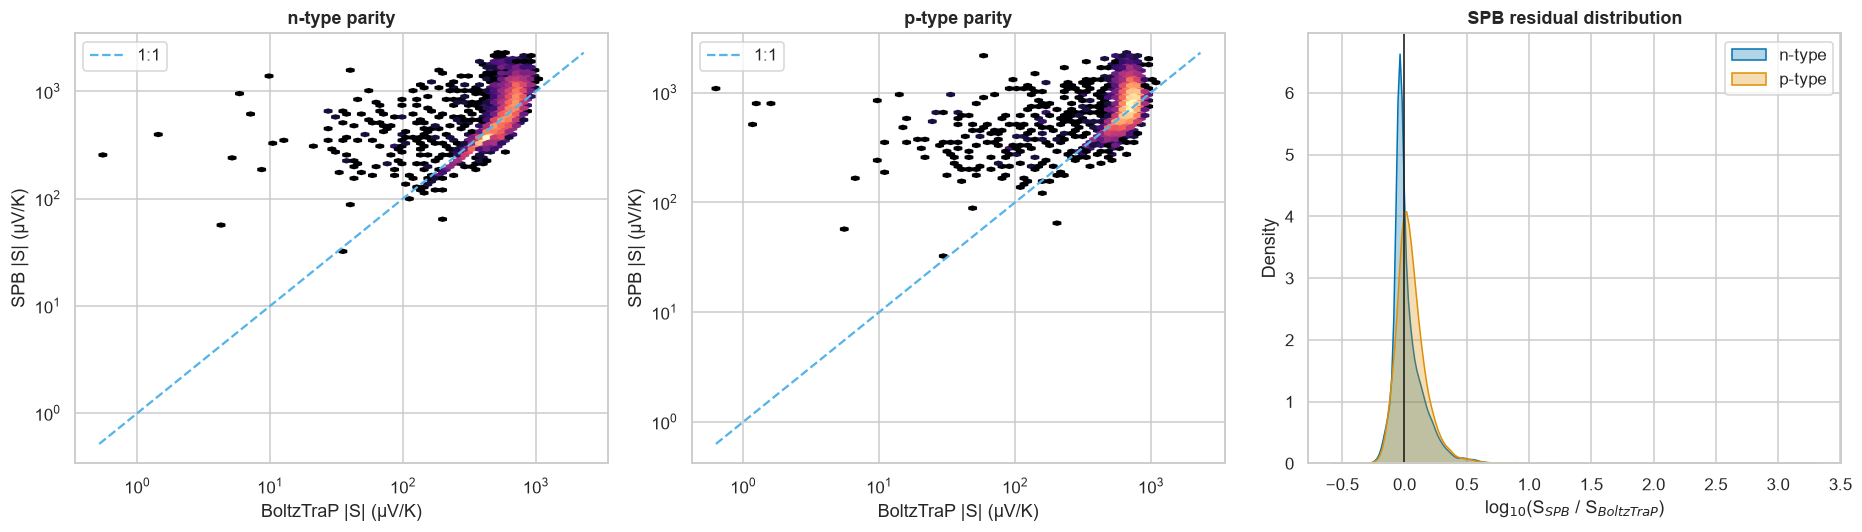

In [15]:
def spb_benchmark(df, carrier):
    m = df[f"m_{carrier}"].where(df[f"m_{carrier}"] > 0)
    S_true = df[f"abs_s_{carrier}"]
    S_pred = pd.Series(spb.seebeck_from_n(CONFIG["dft_doping_cm3"], m.values, CONFIG["T_ref"]), index=df.index)
    ok = S_true.notna() & S_pred.notna() & (S_true > 0)
    ratio = S_pred[ok] / S_true[ok]
    metrics = {
        "carrier": carrier, "n": int(ok.sum()),
        "spearman_rho": stats.spearmanr(S_pred[ok], S_true[ok]).statistic,
        "median_log10_ratio": np.log10(ratio).median(),
        "MdAPE_%": (100 * (ratio - 1).abs()).median(),
        "within_20%": ((ratio - 1).abs() <= 0.2).mean(),
        "SPB_underpredicts": (ratio < 1).mean(),
    }
    return S_pred, metrics


bench_rows = []
for c in ["n", "p"]:
    df_dft[f"S_spb_{c}"], met = spb_benchmark(df_dft, c)
    bench_rows.append(met)
spb_bench = pd.DataFrame(bench_rows).set_index("carrier")
display(spb_bench)
SUMMARY["DFT: SPB(m_c) vs BoltzTraP Spearman (n / p)"] = f"{spb_bench.loc['n','spearman_rho']:.2f} / {spb_bench.loc['p','spearman_rho']:.2f}"
SUMMARY["DFT: SPB(m_c) MdAPE % (n / p)"] = f"{spb_bench.loc['n','MdAPE_%']:.1f} / {spb_bench.loc['p','MdAPE_%']:.1f}"

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, c in zip(axes[:2], ["n", "p"]):
    sub = df_dft[[f"abs_s_{c}", f"S_spb_{c}"]].dropna()
    sub = sub[(sub > 0).all(axis=1)]
    hb = ax.hexbin(sub[f"abs_s_{c}"], sub[f"S_spb_{c}"], xscale="log", yscale="log", gridsize=60,
                   bins="log", cmap="magma", mincnt=1)
    lim = [sub.min().min(), sub.max().max()]
    ax.plot(lim, lim, "c--", lw=1.5, label="1:1")
    ax.set(xlabel="BoltzTraP |S| (µV/K)", ylabel="SPB |S| (µV/K)", title=f"{c}-type parity")
    ax.legend()
for c in ["n", "p"]:
    r = np.log10(df_dft[f"S_spb_{c}"] / df_dft[f"abs_s_{c}"]).replace([np.inf, -np.inf], np.nan).dropna()
    sns.kdeplot(r, ax=axes[2], label=f"{c}-type", fill=True, alpha=0.3)
axes[2].axvline(0, c="k", lw=1)
axes[2].set(xlabel="log$_{10}$(S$_{SPB}$ / S$_{BoltzTraP}$)", title="SPB residual distribution")
axes[2].legend()
fig.tight_layout()
save_fig(fig, "01_dft_spb_parity")
plt.show()

### 1.10 Seebeck effective mass and Fermi-surface complexity factor
Inverting the SPB relation on the BoltzTraP |S| yields the Seebeck mass $m_S^*$ (an effective density-of-states mass). Following Gibbs et al. (2017), the Fermi-surface complexity factor

$$N_V^* K^* = \left(\frac{m_S^*}{m_c^*}\right)^{3/2}$$

captures valley degeneracy and anisotropy; values well above 1 indicate complex band structures favourable for high power factor. The relation between complexity factor and power factor, and its dependence on chemistry, are examined below.

,count,mean,std,min,5%,25%,50%,75%,95%,max
m_S_n,"8,922",4.096,5.395,0.002054,0.3678,0.776,2.147,5.742,12.94,178.2
m_S_p,"8,920",7.97,5.57,0.00285,1.277,4.213,7.076,10.66,17.63,141.3
complexity_n,"8,922",1.443,1.845,7.494e-12,0.0015,0.2459,1.34,1.614,4.888,32.82
complexity_p,"8,920",1.438,2.977,1.038e-11,0.001041,0.08625,0.5219,1.488,6.13,96.23


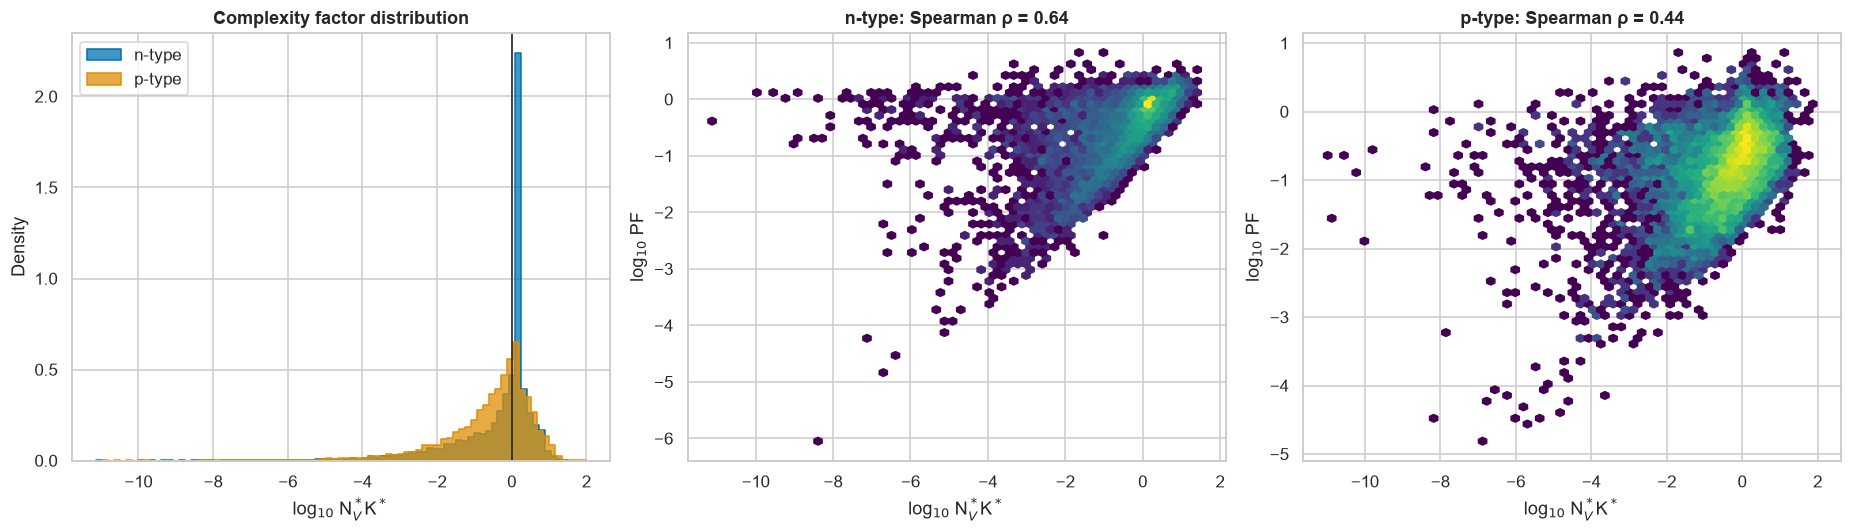

,median complexity_n,median complexity_p
chem_class,,
intermetallic/other,3.184,1.528
hydride,1.936,1.524
chalcogenide,1.464,1.377
pnictide,1.51,1.187
elemental,1.622,1.045
oxide,1.339,0.4225
halide,0.804,0.3067


In [16]:
for c in ["n", "p"]:
    df_dft[f"m_S_{c}"] = spb.seebeck_mass(df_dft[f"abs_s_{c}"].values, CONFIG["dft_doping_cm3"], CONFIG["T_ref"])
    ratio = df_dft[f"m_S_{c}"] / df_dft[f"m_{c}"].where(df_dft[f"m_{c}"] > 0)
    df_dft[f"complexity_{c}"] = ratio ** 1.5
    df_dft[f"log10_complexity_{c}"] = np.log10(df_dft[f"complexity_{c}"].where(df_dft[f"complexity_{c}"] > 0))

cf_stats = df_dft[["m_S_n", "m_S_p", "complexity_n", "complexity_p"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
display(cf_stats)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for c in ["n", "p"]:
    sns.histplot(df_dft[f"log10_complexity_{c}"].dropna(), bins=80, ax=axes[0], label=f"{c}-type",
                 element="step", stat="density")
axes[0].axvline(0, c="k", lw=1)
axes[0].set(xlabel="log$_{10}$ N$_V^*$K$^*$", title="Complexity factor distribution")
axes[0].legend()

for ax, c in zip(axes[1:], ["n", "p"]):
    sub = df_dft[[f"log10_complexity_{c}", f"log10_pf_{c}"]].replace([np.inf, -np.inf], np.nan).dropna()
    ax.hexbin(sub.iloc[:, 0], sub.iloc[:, 1], gridsize=60, bins="log", cmap="viridis", mincnt=1)
    rho = stats.spearmanr(sub.iloc[:, 0], sub.iloc[:, 1]).statistic
    ax.set(xlabel="log$_{10}$ N$_V^*$K$^*$", ylabel="log$_{10}$ PF", title=f"{c}-type: Spearman ρ = {rho:.2f}")
fig.tight_layout()
save_fig(fig, "01_dft_complexity_factor")
plt.show()

display(df_dft.groupby("chem_class")[["complexity_n", "complexity_p"]].median()
        .sort_values("complexity_p", ascending=False).rename(columns=lambda s: f"median {s}"))

### 1.11 Leading candidates and polymorph spread
Top compounds ranked by power factor for each carrier type, and the spread of |S| among polymorphs sharing the same reduced formula. Polymorph spread sets a floor on the precision achievable when matching experiments by composition alone.

In [17]:
show_cols = ["mpid", "formula", "chem_class", "crystal_system", "s_n", "s_p", "pf_n", "pf_p",
             "m_n", "m_p", "complexity_n", "complexity_p"]
show_cols = [c for c in show_cols if c in df_dft]
for c in ["n", "p"]:
    header(f"Top 15 {c}-type compounds by power factor")
    display(df_dft.nlargest(15, f"pf_{c}")[show_cols])

poly = df_dft.groupby("reduced_formula").agg(
    n_polymorphs=("mpid", "size") if "mpid" in df_dft else ("formula", "size"),
    s_n_min=("s_n", "min"), s_n_max=("s_n", "max"), s_p_min=("s_p", "min"), s_p_max=("s_p", "max"))
poly = poly[poly["n_polymorphs"] > 1]
poly["s_p_range"] = poly["s_p_max"] - poly["s_p_min"]
poly["s_n_range"] = poly["s_n_max"] - poly["s_n_min"]
print(f"Formulas with multiple polymorphs: {len(poly)} "
      f"({poly['n_polymorphs'].sum()} entries, {poly['n_polymorphs'].sum() / len(df_dft):.1%} of dataset)")
print(f"Median |S| spread across polymorphs: n-type {poly['s_n_range'].median():.1f} µV/K, "
      f"p-type {poly['s_p_range'].median():.1f} µV/K")
display(poly.sort_values("n_polymorphs", ascending=False).head(10))

**Top 15 n-type compounds by power factor**

,mpid,formula,chem_class,crystal_system,s_n,s_p,pf_n,pf_p,m_n,m_p,complexity_n,complexity_p
6553,mp-755031,KPrPCO7,oxide,monoclinic,97.1,97.1,6.71,6.77,0.625,0.629,0.02202,0.02181
8677,mp-853163,Li4Co(OF)2,halide,monoclinic,-167,-169,6.19,6.36,0.457,0.478,0.1025,0.09851
6923,mp-760432,Cu2O3,oxide,orthorhombic,-200,-199,4.57,4.5,0.031,0.0315,9.003,8.676
4955,mp-634105,HBr,halide,orthorhombic,-514,836,4.27,0.22,3.69,10.4,0.2955,2.627
6123,mp-721650,CaH14I10O7,oxide,triclinic,-477,624,4.15,0.3,183,"1,330",0.0005499,0.0001551
7230,mp-763970,V4O7F5,halide,triclinic,-111,-114,4.07,4.04,0.571,0.615,0.03197,0.03004
2709,mp-540925,Hg2AsF6,halide,monoclinic,-558,572,3.96,3.59,36.2,70.2,0.01604,0.00699
753,mp-19390,WO3,oxide,cubic,-576,767,3.61,0.463,0.259,2.02,32.67,13.78
1904,mp-29803,SiH,hydride,trigonal,-628,563,3.38,2.18,2.19,103,2.431,0.003542
7126,mp-763062,LiNiPO4,oxide,triclinic,88.7,90.6,3.32,3.38,0.355,0.346,0.04412,0.04751


**Top 15 p-type compounds by power factor**

,mpid,formula,chem_class,crystal_system,s_n,s_p,pf_n,pf_p,m_n,m_p,complexity_n,complexity_p
4694,mp-614013,CsSnI3,halide,cubic,-481,180,2.01,7.29,0.325,0.0896,7.698,1.408
7130,mp-763096,VO2F,halide,trigonal,-749,507,0.627,7.25,2.57,0.239,7.792,16.52
6553,mp-755031,KPrPCO7,oxide,monoclinic,97.1,97.1,6.71,6.77,0.625,0.629,0.02202,0.02181
4407,mp-570875,Ga2Os,intermetallic/other,orthorhombic,-682,307,0.86,6.66,1.55,0.269,7.644,1.321
8677,mp-853163,Li4Co(OF)2,halide,monoclinic,-167,-169,6.19,6.36,0.457,0.478,0.1025,0.09851
5679,mp-691,SnSe,chalcogenide,orthorhombic,-543,414,2.59,5.61,0.618,0.38,6.041,2.785
192,mp-12910,GeS,chalcogenide,orthorhombic,-485,352,2.08,4.84,1.59,0.344,0.7453,1.56
219,mp-13313,ScTlSe2,chalcogenide,trigonal,-670,350,1.05,4.6,3.51,0.421,1.951,1.125
410,mp-16035,Gd2TeO2,oxide,tetragonal,-840,552,0.0667,4.6,31,1.55,0.5348,1.689
6923,mp-760432,Cu2O3,oxide,orthorhombic,-200,-199,4.57,4.5,0.031,0.0315,9.003,8.676


Formulas with multiple polymorphs: 812 (2356 entries, 26.4% of dataset)
Median |S| spread across polymorphs: n-type 46.0 µV/K, p-type 67.5 µV/K


,n_polymorphs,s_n_min,s_n_max,s_p_min,s_p_max,s_p_range,s_n_range
reduced_formula,,,,,,,
SiO2,61,-517,-389,162,"1,090",928,128
CdI2,26,-581,-516,667,721,54,65
LiMnPO4,19,-778,-372,537,790,253,406
LiCoPO4,16,-780,194,-183,819,"1,002",974
LiFeSiO4,15,-797,-602,564,770,206,195
Hf2N2O,15,-489,-426,568,697,129,63
Al(HO)3,14,-394,-384,655,825,170,10
LiSb(PO3)4,12,-756,-532,632,768,136,224
AlPO4,12,-451,-402,642,"1,060",418,49


## 2. teMatDb272 (Ryu et al., 2025)

### 2.1 Repository discovery
Lists the full repository tree in a single GitHub API call and selects tabular files (CSV/XLSX), preferring the `teMatDb_publication` directory. A `GITHUB_TOKEN` stored in Colab *Secrets* raises the API limit from 60 to 5,000 requests per hour.

In [18]:
def github_tree(repo, token=None):
    headers = {"Accept": "application/vnd.github+json"}
    if token:
        headers["Authorization"] = f"Bearer {token}"
    meta = SESSION.get(f"https://api.github.com/repos/{repo}", headers=headers, timeout=30)
    meta.raise_for_status()
    branch = meta.json().get("default_branch", "main")
    tree = SESSION.get(f"https://api.github.com/repos/{repo}/git/trees/{branch}?recursive=1",
                       headers=headers, timeout=60)
    tree.raise_for_status()
    blobs = pd.DataFrame([t for t in tree.json().get("tree", []) if t.get("type") == "blob"])
    blobs["ext"] = blobs["path"].str.extract(r"\.([A-Za-z0-9]+)$")[0].str.lower()
    blobs["raw_url"] = [f"https://raw.githubusercontent.com/{repo}/{branch}/{requests.utils.quote(p)}"
                        for p in blobs["path"]]
    blobs["size_mb"] = blobs["size"].fillna(0) / 1e6
    return blobs, branch


tematdb_files = pd.DataFrame()
try:
    repo_tree, repo_branch = github_tree(CONFIG["tematdb_repo"], get_github_token())
    tabular = repo_tree[repo_tree["ext"].isin(["csv", "tsv", "xlsx", "xls"])].copy()
    preferred = tabular[tabular["path"].str.contains(CONFIG["tematdb_preferred_dir"], case=False)]
    tematdb_files = preferred if len(preferred) else tabular
    tematdb_files = tematdb_files[tematdb_files["size_mb"] <= CONFIG["tematdb_max_file_mb"]]
    tematdb_files = (tematdb_files.assign(_rank=tematdb_files["ext"].map({"csv": 0, "tsv": 0}).fillna(1))
                     .sort_values(["_rank", "size_mb"], ascending=[True, False])
                     .head(CONFIG["tematdb_max_files"]).drop(columns="_rank"))
    print(f"Branch: {repo_branch} | files in repo: {len(repo_tree)} | tabular: {len(tabular)} | selected: {len(tematdb_files)}")
    display(repo_tree["ext"].value_counts().head(10).rename("files").to_frame().T)
    display(tematdb_files[["path", "ext", "size_mb"]])
except Exception as exc:
    print(f"GitHub discovery failed: {exc}")
    print("Add a GITHUB_TOKEN in Colab Secrets, or browse "
          f"https://github.com/{CONFIG['tematdb_repo']} and populate `tematdb_files` manually "
          "with columns ['path', 'ext', 'raw_url'].")

Branch: main | files in repo: 577 | tabular: 67 | selected: 3


ext,pyc,py,png,csv,xlsx,txt,vtk,db,feather,json
files,189,180,75,33,30,27,10,7,6,4


,path,ext,size_mb
537,teMatDb_publication/teMatDb272_dataset_2025051...,csv,4.893
538,teMatDb_publication/teMatDb272_dataset_2025051...,csv,0.5374
539,teMatDb_publication/teMatDb272_dataset_2025051...,csv,0.03499


### 2.2 Loading tables
Downloads each selected file (cached locally). Every worksheet of an Excel workbook is loaded as a separate table. An inventory of shapes and leading columns is displayed.

In [19]:
def read_tabular(content, ext):
    if ext in ("csv", "tsv"):
        sep = "\t" if ext == "tsv" else None
        for enc in ("utf-8", "latin-1"):
            try:
                return {"": pd.read_csv(io.BytesIO(content), sep=sep, engine="python", encoding=enc)}
            except UnicodeDecodeError:
                continue
    return pd.read_excel(io.BytesIO(content), sheet_name=None)


tematdb_tables = {}
for _, f in tqdm(list(tematdb_files.iterrows()), desc="teMatDb files"):
    try:
        content = fetch_bytes(f["raw_url"], cache_name=f"tematdb/{f['path']}")
        for sheet, table in read_tabular(content, f["ext"]).items():
            key = f"{f['path']}::{sheet}" if sheet else f["path"]
            table.columns = [str(c).strip() for c in table.columns]
            tematdb_tables[key] = table
    except Exception as exc:
        print(f"Failed: {f['path']} -> {exc}")

inventory = pd.DataFrame([{"table": k, "rows": v.shape[0], "cols": v.shape[1],
                           "columns": ", ".join(map(str, v.columns[:10])) + (" ..." if v.shape[1] > 10 else "")}
                          for k, v in tematdb_tables.items()])
display(inventory)

teMatDb files:   0%|          | 0/3 [00:00<?, ?it/s]

,table,rows,cols,columns
0,teMatDb_publication/teMatDb272_dataset_2025051...,56641,6,"﻿sample_id, Temperature, alpha, rho, kappa, ZT..."
1,teMatDb_publication/teMatDb272_dataset_2025051...,14717,4,"﻿sample_id, tepname, Temperature, tepvalue"
2,teMatDb_publication/teMatDb272_dataset_2025051...,272,12,"﻿sample_id, YEAR, DOI, figure_number_of_target..."


### 2.3 Automatic schema detection
Identifies (i) property-versus-temperature tables that contain Seebeck data, supporting both *wide* layouts (temperature and Seebeck columns) and *tidy* layouts (a property-name column with x/y value columns), and (ii) the sample-level metadata table (group, base material, composition, processing). Temperatures are converted to kelvin and Seebeck coefficients to µV/K based on magnitude. Column choices can be fixed through `COLUMN_OVERRIDES["tematdb"]`.

In [20]:
ID_PAT = r"sample.?id|^sampleid$|^id$|^sample$|tematdb.?id|^sample.?no|^no\.?$"
TEMP_PAT = r"^t$|^t[\s_(\[]|^temp|temperature"
SEEBECK_PAT = r"seebeck|thermopower|^alpha|^s$|^s[\s_(\[]"
SEEBECK_VALUE_PAT = r"seebeck|thermopower|^alpha(?:[\s_]|$)|^s$"
META_PAT = r"group|basemat|base.?mat|composition|formula|sinter|family|dopant|doi|reference|year|process"


def normalize_temperature(T):
    if T.min() < 0:
        return T + 273.15, "°C -> K"
    return T, "K"


def normalize_seebeck(S):
    med = S.abs().median()
    if med < 1e-2:
        return S * 1e6, "V/K -> µV/K"
    if med < 1:
        return S * 1e3, "mV/K -> µV/K"
    return S, "µV/K"


def extract_seebeck_long(df, default_id, overrides):
    id_col = find_col(df, ID_PAT, override=overrides.get("sample_id"))
    t_col = find_col(df, TEMP_PAT, exclude=r"unit|range|max|min", override=overrides.get("temperature"))
    s_col = find_col(df, SEEBECK_PAT, exclude=r"unit|err|std|sigma", override=overrides.get("seebeck"))
    ids = df[id_col] if id_col is not None else pd.Series(default_id, index=df.index)
    if t_col is not None and s_col is not None:
        out = pd.DataFrame({"sample_id": ids, "T": df[t_col], "S": df[s_col]})
        layout = f"wide ({t_col}, {s_col})"
    else:
        prop_col = None
        for c in df.columns:
            if pd.api.types.is_numeric_dtype(df[c]):
                continue
            if df[c].dropna().astype(str).str.strip().str.contains(SEEBECK_VALUE_PAT, case=False, regex=True).any():
                prop_col = c
                break
        x_col = find_col(df, r"^x$|^value_?x$|^x_?val") or t_col
        y_col = find_col(df, r"^y$|^value_?y$|^value$|^val$|^y_?val")
        if prop_col is None or x_col is None or y_col is None:
            return None
        mask = df[prop_col].astype(str).str.strip().str.contains(SEEBECK_VALUE_PAT, case=False, regex=True)
        out = pd.DataFrame({"sample_id": ids[mask], "T": df.loc[mask, x_col], "S": df.loc[mask, y_col]})
        layout = f"tidy ({prop_col}: {x_col}, {y_col})"
    out["T"] = pd.to_numeric(out["T"], errors="coerce")
    out["S"] = pd.to_numeric(out["S"], errors="coerce")
    out = out.dropna(subset=["T", "S"])
    if len(out) < 3:
        return None
    out["T"], t_note = normalize_temperature(out["T"])
    out["S"], s_note = normalize_seebeck(out["S"])
    out["sample_id"] = out["sample_id"].astype(str).str.strip()
    out.attrs["info"] = {"layout": layout, "id_col": id_col, "T_unit": t_note, "S_unit": s_note}
    return out


tep_parts, tep_info = [], []
meta_candidates = []
for key, table in tematdb_tables.items():
    long_df = extract_seebeck_long(table, key, COLUMN_OVERRIDES["tematdb"])
    if long_df is not None:
        long_df["source_table"] = key
        tep_parts.append(long_df)
        tep_info.append({"table": key, "points": len(long_df), **long_df.attrs["info"]})
    else:
        score = sum(bool(re.search(META_PAT, c, re.I)) for c in table.columns)
        if score and find_col(table, ID_PAT) is not None:
            meta_candidates.append((score, len(table), key))

df_tep = pd.concat(tep_parts, ignore_index=True) if tep_parts else pd.DataFrame(columns=["sample_id", "T", "S"])
df_meta, meta_key = None, None
if meta_candidates:
    meta_key = sorted(meta_candidates, reverse=True)[0][2]
    df_meta = tematdb_tables[meta_key].copy()

header("Seebeck tables detected")
display(pd.DataFrame(tep_info))
print(f"Metadata table: {meta_key}")
if df_meta is not None:
    display(df_meta.head())
print(f"Seebeck points: {len(df_tep)} | samples: {df_tep['sample_id'].nunique()}")

**Seebeck tables detected**

,table,points,layout,id_col,T_unit,S_unit
0,teMatDb_publication/teMatDb272_dataset_2025051...,56641,"wide (Temperature, alpha)",﻿sample_id,K,V/K -> µV/K


Metadata table: teMatDb_publication/teMatDb272_dataset_20250515/teMatDb_samples.csv


,﻿sample_id,YEAR,DOI,figure_number_of_targetZT,label_of_targetZT_in_figure,figure_label_description,"mat_dimension(bulk, film, 1D, 2D)",GROUP,BASEMAT,Composition_by_element,Composition_detailed,SINTERING
0,1,"2,011",10.1038/NCHEM.955,Figure 4,2% SrTe,PbTe-1%SrTe-2%SrTe,Bulk,PbTe,PbTe,PbTe SrTe NaTe,(PbTe)0.97(SrTe)0.02(Na2Te)0.01,na
1,4,"2,015",10.1038/ncomms9144,Figure 2(a),x = 0.12,FeNb1-x Hfx Sb,Bulk,HH,HH,FeNbHfSb,FeNb0.88Hf0.12Sb,SPS
2,6,"2,015",10.1002/adma.201501030,Figure 1(b),Cu2S0.52Te0.48,NaN,Bulk,Cu2Q,M2Q,CuSTe,Cu2S0.52Te0.48,SPS
3,7,"2,008",10.1126/science.1159725,Figure 1(b),2% Tl,Tl0.02Pb0.98Te,Bulk,PbTe,PbTe,TlPbTe,Tl0.02Pb0.98Te,HP
4,9,"2,014",10.1038/am.2013.86,Figure 8(a),HD-Sb1.7,NaN,Bulk,Bi2Te3,Bi2Te3,BiSbTe,Bi0.3Sb1.7Te3,HP


Seebeck points: 56641 | samples: 272


### 2.4 Metadata profile and carrier-concentration availability
Missingness of the sample metadata, distributions of the group, base-material and processing fields, and a search of all loaded tables for carrier-concentration or Hall data.

Carrier-concentration-like columns: none found
id: ﻿sample_id | group: GROUP | basemat: BASEMAT | composition: Composition_by_element | process: SINTERING


,dtype,n_missing,pct_missing,n_unique
SINTERING,object,125,45.96,5
"mat_dimension(bulk, film, 1D, 2D)",object,67,24.63,5
figure_label_description,object,38,13.97,231
﻿sample_id,int64,0,0,272
figure_number_of_targetZT,object,0,0,115
DOI,object,0,0,262
YEAR,float64,0,0,24
label_of_targetZT_in_figure,object,0,0,252
GROUP,object,0,0,20
BASEMAT,object,0,0,42


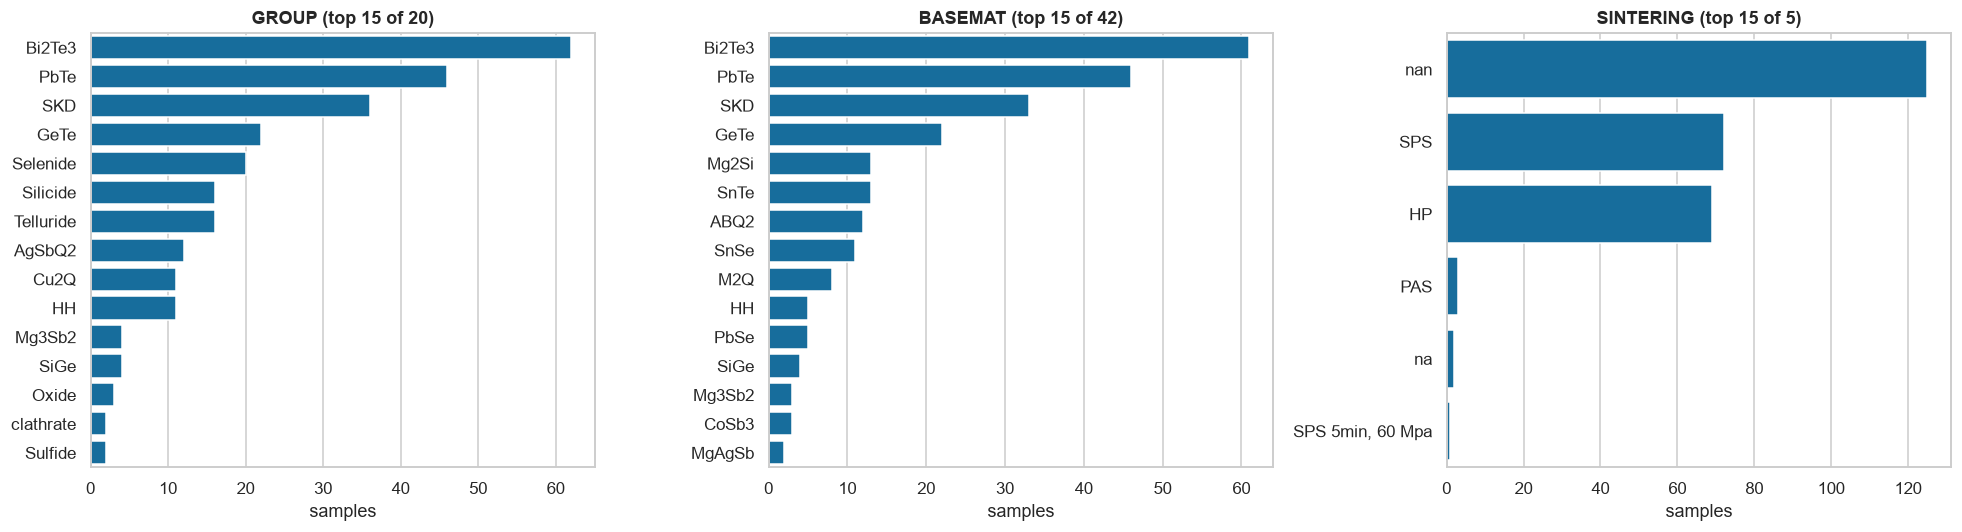

In [21]:
CARRIER_PAT = r"carrier|hall|doping.?level|conc|\bn_h\b|^n_?\(?cm"
carrier_hits = {k: [c for c in t.columns if re.search(CARRIER_PAT, c, re.I)] for k, t in tematdb_tables.items()}
carrier_hits = {k: v for k, v in carrier_hits.items() if v}
print(f"Carrier-concentration-like columns: {carrier_hits or 'none found'}")
SUMMARY["teMatDb: carrier concentration available"] = bool(carrier_hits)

O = COLUMN_OVERRIDES["tematdb"]
meta_id_col = find_col(df_meta, ID_PAT, override=O["sample_id"])
group_col = find_col(df_meta, r"^group$|group|family|class", override=O["group"])
basemat_col = find_col(df_meta, r"basemat|base.?mat|matrix|host", override=O["basemat"])
comp_col = find_col(df_meta, r"composition|formula|nominal", exclude=r"basemat", override=O["composition"])
process_col = find_col(df_meta, r"sinter|process|synthes|method")

if df_meta is not None:
    print(f"id: {meta_id_col} | group: {group_col} | basemat: {basemat_col} | composition: {comp_col} | process: {process_col}")
    display(missingness_report(df_meta).head(25))
    cat_cols = [c for c in [group_col, basemat_col, process_col] if c is not None]
    if cat_cols:
        fig, axes = plt.subplots(1, len(cat_cols), figsize=(6 * len(cat_cols), 5))
        for ax, c in zip(np.atleast_1d(axes), cat_cols):
            vc = df_meta[c].astype(str).value_counts().head(15)
            sns.barplot(x=vc.values, y=vc.index, ax=ax, color="C0")
            ax.set(xlabel="samples", ylabel="", title=f"{c} (top 15 of {df_meta[c].nunique()})")
        fig.tight_layout()
        save_fig(fig, "02_tematdb_metadata")
        plt.show()

### 2.5 Curve-level feature extraction
For every sample the S(T) curve is reduced to physically interpretable descriptors:

| Feature | Definition |
|---|---|
| `n_points`, `T_min`, `T_max`, `T_span` | sampling density and temperature coverage |
| `carrier_type` | sign of the median Seebeck coefficient |
| `S_ref` | S at the reference temperature (interpolated, or nearest point within the tolerance window) |
| `S_abs_max`, `T_at_S_max` | peak \|S\| and its temperature |
| `interior_peak` | \|S\| maximum well below `T_max` — signature of bipolar conduction onset |
| `sign_change` | S crosses zero within the measured range |
| `low_T_slope` | d\|S\|/dT over the lowest 150 K (degenerate-limit indicator) |
| `eta_ref` | SPB reduced Fermi level at `T_ref` |
| `n_over_m15_ref` | SPB-inferred $n/(m^*/m_e)^{3/2}$ at `T_ref` (cm⁻³) |
| `Eg_goldsmid_eV` | Goldsmid–Sharp band-gap estimate $E_g \approx 2e\,S_{max}T_{max}$ (only for interior peaks) |

In [22]:
def curve_features(g, T_ref, window):
    g = g.groupby("T", as_index=False)["S"].mean().sort_values("T")
    T, S = g["T"].to_numpy(), g["S"].to_numpy()
    absS = np.abs(S)
    i_max = int(np.argmax(absS))
    feat = {"n_points": len(T), "T_min": T.min(), "T_max": T.max(), "T_span": T.max() - T.min(),
            "carrier_type": "p" if np.median(S) > 0 else "n",
            "S_abs_max": absS[i_max], "T_at_S_max": T[i_max],
            "interior_peak": bool(len(T) >= 4 and T[i_max] < T.max() - 25 and absS[-1] < 0.97 * absS[i_max]),
            "sign_change": bool(np.any(np.sign(S[:-1]) * np.sign(S[1:]) < 0))}
    if T.min() <= T_ref <= T.max():
        feat["S_ref"] = float(np.interp(T_ref, T, S))
    elif np.min(np.abs(T - T_ref)) <= window:
        feat["S_ref"] = float(S[np.argmin(np.abs(T - T_ref))])
    else:
        feat["S_ref"] = np.nan
    low = T <= T.min() + 150
    feat["low_T_slope"] = np.polyfit(T[low], absS[low], 1)[0] if low.sum() >= 3 else np.nan
    feat["eta_ref"] = float(spb.eta_from_seebeck(abs(feat["S_ref"]))) if np.isfinite(feat["S_ref"]) else np.nan
    feat["n_over_m15_ref"] = float(spb.reduced_density(abs(feat["S_ref"]), T_ref)) if np.isfinite(feat["S_ref"]) else np.nan
    feat["Eg_goldsmid_eV"] = 2 * absS[i_max] * 1e-6 * T[i_max] if feat["interior_peak"] else np.nan
    return pd.Series(feat)


df_curves = pd.DataFrame()
if len(df_tep):
    df_curves = (df_tep.groupby("sample_id")
                 .apply(lambda g: curve_features(g, CONFIG["T_ref"], CONFIG["T_window"]))
                 .reset_index())
    if df_meta is not None and meta_id_col is not None:
        meta_cols = [c for c in [meta_id_col, group_col, basemat_col, comp_col, process_col] if c is not None]
        meta_small = df_meta[list(dict.fromkeys(meta_cols))].copy()
        meta_small["sample_id"] = meta_small[meta_id_col].astype(str).str.strip()
        df_curves = df_curves.merge(meta_small.drop_duplicates("sample_id"), on="sample_id", how="left")
        match_rate = df_curves[meta_id_col].notna().mean()
        print(f"Curves matched to metadata: {match_rate:.1%}")
    df_curves["usable_for_fit"] = df_curves["n_points"] >= CONFIG["min_points_per_curve"]

    SUMMARY["teMatDb: samples with S(T)"] = len(df_curves)
    SUMMARY["teMatDb: Seebeck points"] = len(df_tep)
    SUMMARY[f"teMatDb: curves with >= {CONFIG['min_points_per_curve']} points"] = int(df_curves["usable_for_fit"].sum())
    SUMMARY["teMatDb: curves with interior |S| peak (bipolar)"] = f"{df_curves['interior_peak'].mean():.1%}"
    display(df_curves.describe(include="all").T)

Curves matched to metadata: 100.0%


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sample_id,272,272,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_points,272,NaN,NaN,NaN,208.2,82.11,45,137,217,259.2,451
T_min,272,NaN,NaN,NaN,306.4,53.59,4,302,304,322,484
T_max,272,NaN,NaN,NaN,720.8,176.9,284,572,761,844.5,"1,200"
T_span,272,NaN,NaN,NaN,414.5,164.2,88,272,432,516.5,900
carrier_type,272,2,p,145,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S_abs_max,272,NaN,NaN,NaN,226.6,66.66,46.99,186.8,215.7,259.4,548
T_at_S_max,272,NaN,NaN,NaN,661,198.7,284,472,713,800,"1,200"
interior_peak,272,2,False,183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sign_change,272,1,False,272,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.6 Sampling density and temperature coverage
Distribution of points per curve (SPB fitting requires sufficient points for numerical stability), the measured temperature window of each sample, and the carrier-type split.

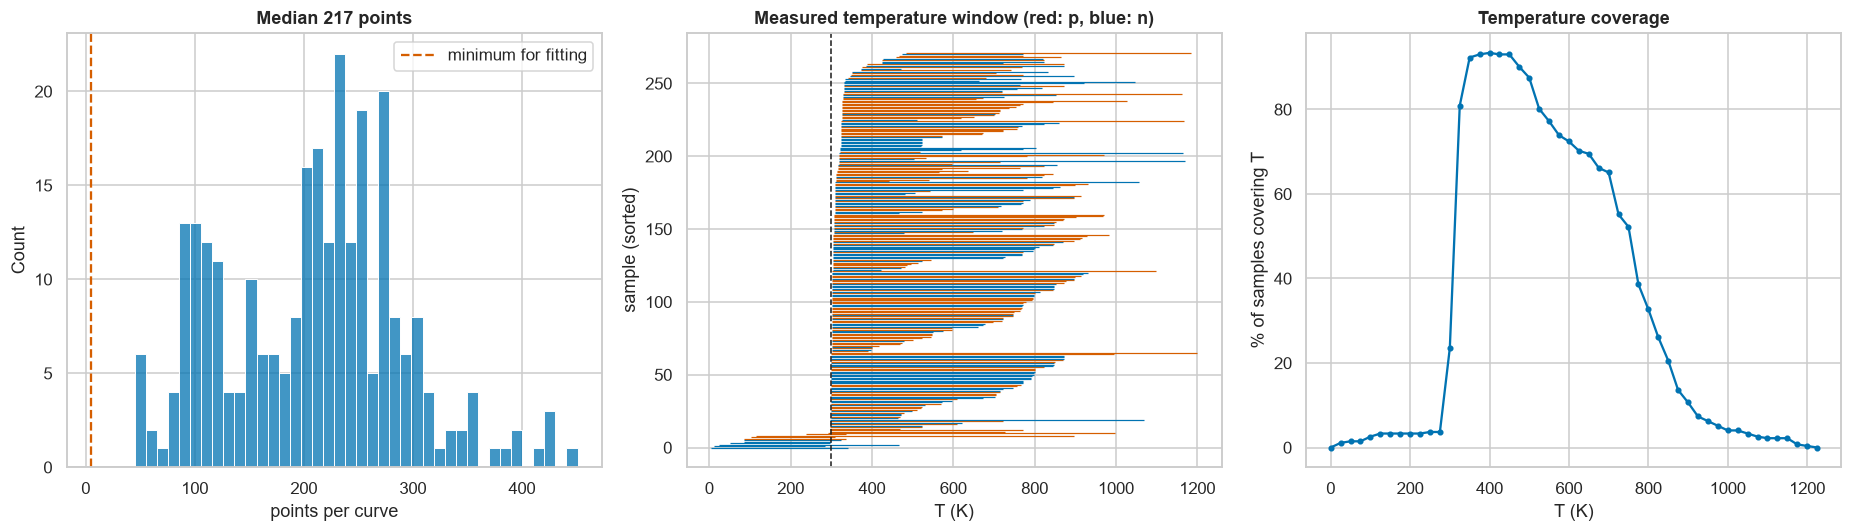

carrier_type,p,n
samples,145,127


In [23]:
if len(df_curves):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    sns.histplot(df_curves["n_points"], bins=40, ax=axes[0])
    axes[0].axvline(CONFIG["min_points_per_curve"], c="r", ls="--", label="minimum for fitting")
    axes[0].set(xlabel="points per curve", title=f"Median {df_curves['n_points'].median():.0f} points")
    axes[0].legend()

    ordered = df_curves.sort_values(["T_min", "T_max"]).reset_index(drop=True)
    axes[1].hlines(ordered.index, ordered["T_min"], ordered["T_max"], lw=0.8,
                   colors=np.where(ordered["carrier_type"] == "p", "C3", "C0"))
    axes[1].axvline(CONFIG["T_ref"], c="k", ls="--", lw=1)
    axes[1].set(xlabel="T (K)", ylabel="sample (sorted)", title="Measured temperature window (red: p, blue: n)")

    T_grid = np.arange(0, df_curves["T_max"].max() + 50, 25)
    coverage = [((df_curves["T_min"] <= t) & (df_curves["T_max"] >= t)).mean() for t in T_grid]
    axes[2].plot(T_grid, np.array(coverage) * 100, marker="o", ms=3)
    axes[2].set(xlabel="T (K)", ylabel="% of samples covering T", title="Temperature coverage")
    fig.tight_layout()
    save_fig(fig, "02_tematdb_coverage")
    plt.show()
    display(df_curves["carrier_type"].value_counts().rename("samples").to_frame().T)

### 2.7 Seebeck curves by material group
S(T) curves are plotted in small multiples for the most populated groups. The spread within a group reflects doping and processing variation that is not captured by composition-level descriptors.

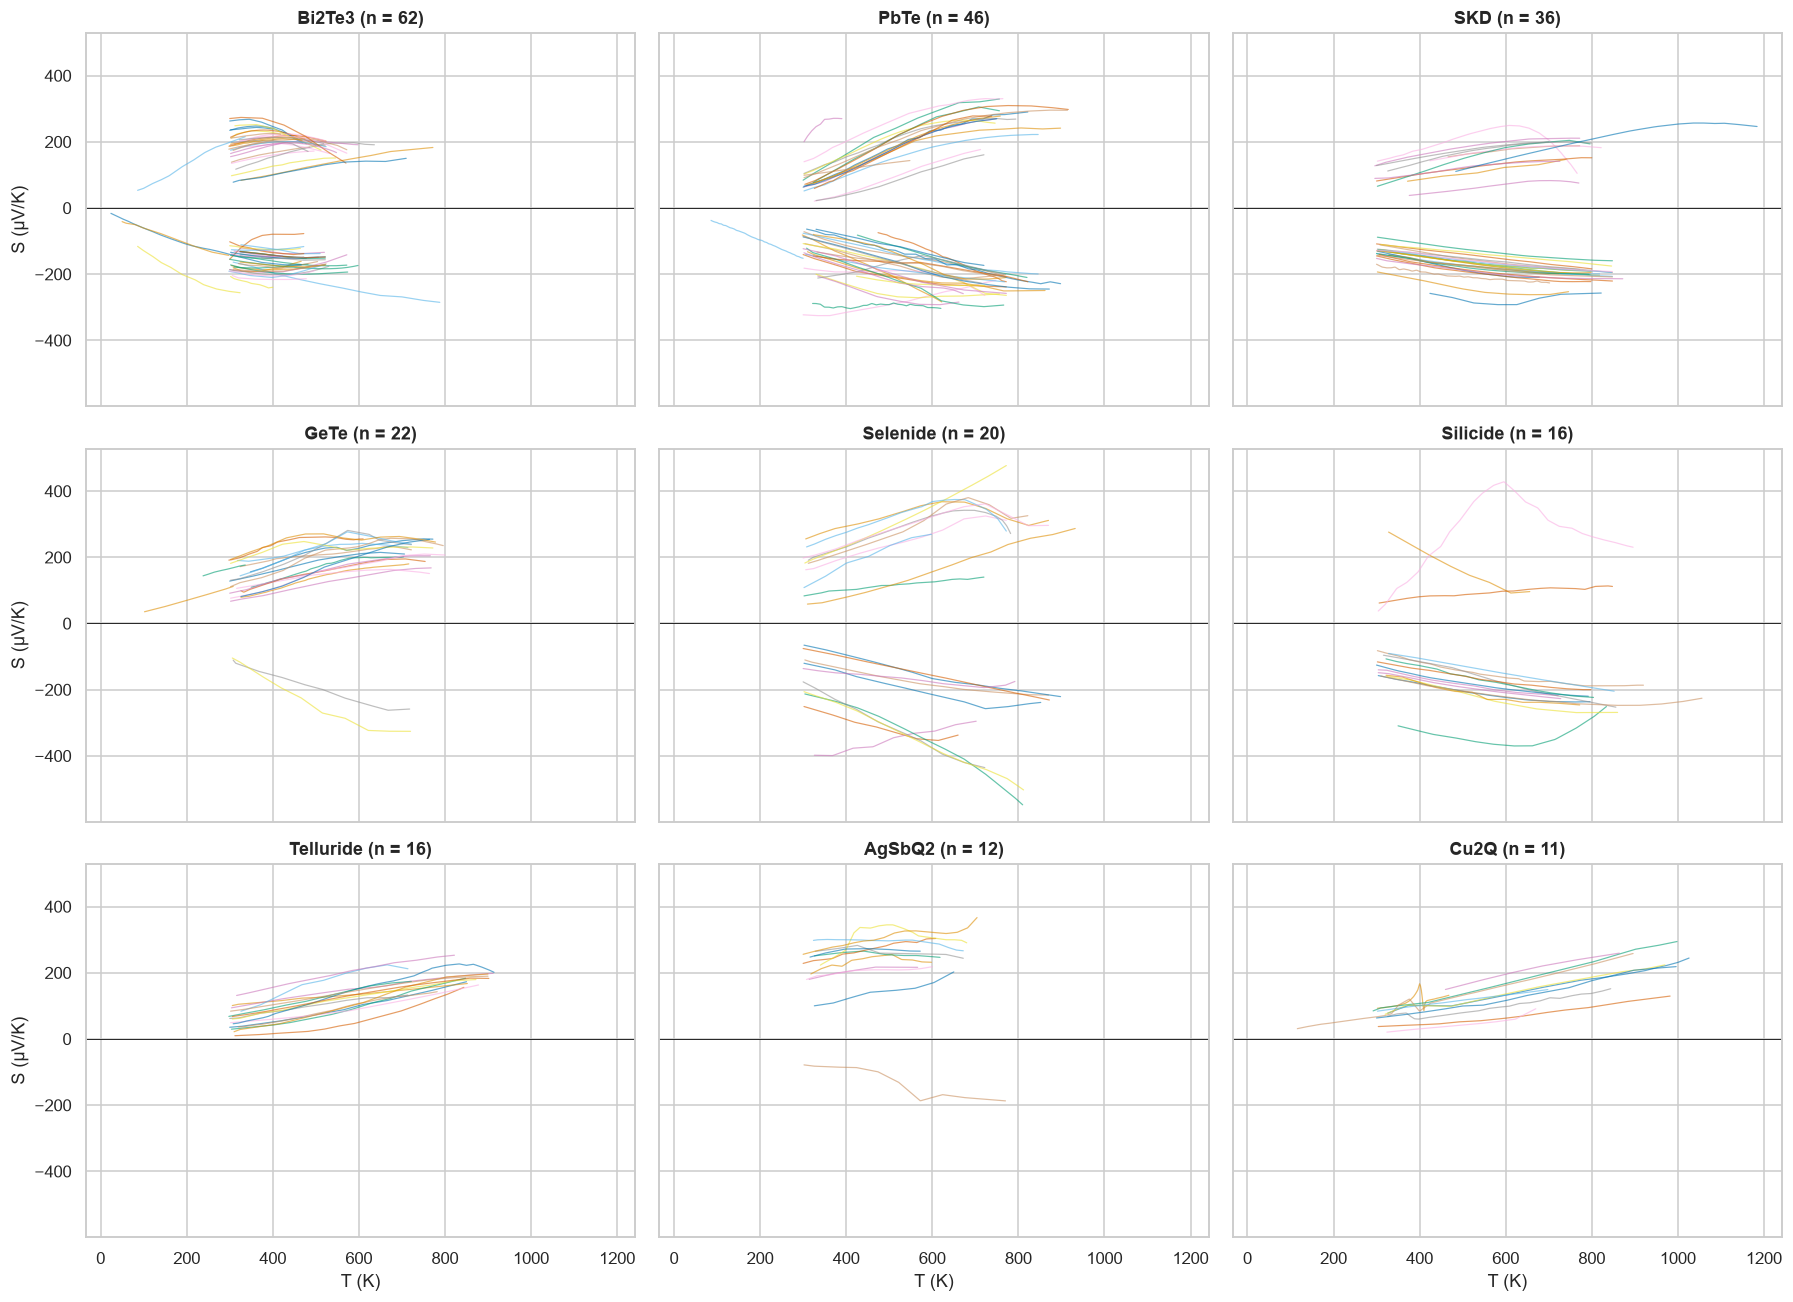

In [24]:
if len(df_curves):
    facet_col = group_col if group_col in df_curves else (basemat_col if basemat_col in df_curves else None)
    plot_df = df_tep.merge(df_curves[["sample_id"] + ([facet_col] if facet_col else [])], on="sample_id")
    if facet_col is None:
        plot_df["group"] = "all samples"
        facet_col = "group"
    plot_df[facet_col] = plot_df[facet_col].astype(str)
    top_groups = plot_df.groupby(facet_col)["sample_id"].nunique().nlargest(9).index
    n_panels = len(top_groups)
    ncols = min(3, n_panels)
    nrows = int(np.ceil(n_panels / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4 * nrows), sharex=True, sharey=True, squeeze=False)
    for ax, grp in zip(axes.flat, top_groups):
        sub = plot_df[plot_df[facet_col] == grp]
        for sid, curve in sub.groupby("sample_id"):
            curve = curve.sort_values("T")
            ax.plot(curve["T"], curve["S"], lw=0.8, alpha=0.6)
        ax.axhline(0, c="k", lw=0.6)
        ax.set_title(f"{grp} (n = {sub['sample_id'].nunique()})")
    for ax in list(axes.flat)[n_panels:]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("T (K)")
    for ax in axes[:, 0]:
        ax.set_ylabel("S (µV/K)")
    fig.tight_layout()
    save_fig(fig, "02_tematdb_curves_by_group")
    plt.show()

### 2.8 Reference-temperature Seebeck, bipolar onset and SPB descriptors
Group-level comparison of $S(T_{ref})$, the frequency of bipolar-onset peaks and the Goldsmid–Sharp gap estimate, together with the SPB-derived reduced Fermi level and $n/(m^*)^{3/2}$. Because no carrier concentration is reported, $n/(m^*)^{3/2}$ is the only SPB-consistent carrier descriptor recoverable from Seebeck data alone.

,samples,median_S_ref,median_abs_S_max,bipolar_fraction,median_Eg_goldsmid_eV,median_eta_ref,median_n_over_m15
GROUP,,,,,,,
Bi2Te3,62,-120.6,194.3,0.5484,0.1682,0.5303,2.866e+19
PbTe,46,-76.39,254.4,0.1522,0.308,2.47,8.927e+19
SKD,36,-126.6,199.7,0.1667,0.3227,1.542,5.514e+19
GeTe,22,128,237.5,0.4091,0.2943,1.549,5.536e+19
Selenide,20,58.51,347.8,0.5,0.4593,0.4863,2.776e+19
Telluride,16,60.13,181.5,0.125,0.3381,4.611,1.983e+20
Silicide,16,-125.7,232.2,0.25,0.4416,1.61,5.734e+19
AgSbQ2,12,212.4,269.2,0.4167,0.2408,-0.1189,1.775e+19
HH,11,116.6,209.4,0.5455,0.2458,1.872,6.624e+19


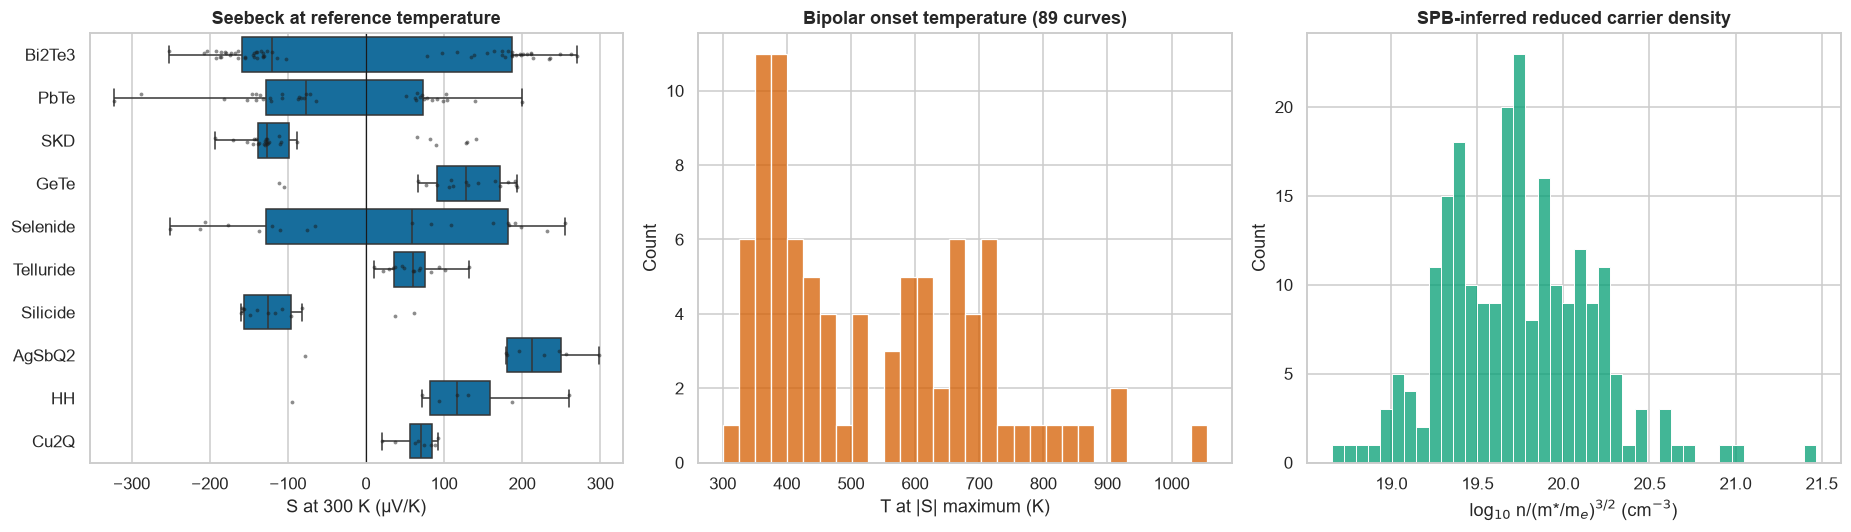

In [25]:
if len(df_curves):
    fc = group_col if group_col in df_curves else "carrier_type"
    grp_stats = (df_curves.assign(_g=df_curves[fc].astype(str))
                 .groupby("_g")
                 .agg(samples=("sample_id", "size"), median_S_ref=("S_ref", "median"),
                      median_abs_S_max=("S_abs_max", "median"), bipolar_fraction=("interior_peak", "mean"),
                      median_Eg_goldsmid_eV=("Eg_goldsmid_eV", "median"), median_eta_ref=("eta_ref", "median"),
                      median_n_over_m15=("n_over_m15_ref", "median"))
                 .sort_values("samples", ascending=False))
    grp_stats.index.name = fc
    display(grp_stats.head(20))

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    top = grp_stats.head(10).index
    sub = df_curves[df_curves[fc].astype(str).isin(top)].assign(_g=lambda d: d[fc].astype(str))
    sns.boxplot(data=sub, y="_g", x="S_ref", ax=axes[0], order=top, color="C0", showfliers=False)
    sns.stripplot(data=sub, y="_g", x="S_ref", ax=axes[0], order=top, color="k", size=2.5, alpha=0.5)
    axes[0].axvline(0, c="k", lw=0.8)
    axes[0].set(xlabel=f"S at {CONFIG['T_ref']:.0f} K (µV/K)", ylabel="", title="Seebeck at reference temperature")

    peaks = df_curves[df_curves["interior_peak"]]
    sns.histplot(peaks["T_at_S_max"], bins=30, ax=axes[1], color="C3")
    axes[1].set(xlabel="T at |S| maximum (K)", title=f"Bipolar onset temperature ({len(peaks)} curves)")

    valid = df_curves["n_over_m15_ref"].replace([np.inf, -np.inf], np.nan).dropna()
    sns.histplot(np.log10(valid[valid > 0]), bins=40, ax=axes[2], color="C2")
    axes[2].set(xlabel="log$_{10}$ n/(m*/m$_e$)$^{3/2}$ (cm$^{-3}$)", title="SPB-inferred reduced carrier density")
    fig.tight_layout()
    save_fig(fig, "02_tematdb_descriptors")
    plt.show()

## 3. ChemDataExtractor Thermoelectric Database (Sierepeklis & Cole, 2022)

### 3.1 Figshare discovery and loading
Queries the Figshare API for the article's file list and loads the principal tabular file (CSV preferred; JSON and ZIP archives are also supported).

In [26]:
def load_figshare_article(article_id):
    meta = SESSION.get(f"https://api.figshare.com/v2/articles/{article_id}", timeout=60)
    meta.raise_for_status()
    article = meta.json()
    files = pd.DataFrame(article.get("files", []))
    return article, files


def read_any(content, name):
    name = name.lower()
    if name.endswith(".csv"):
        return pd.read_csv(io.BytesIO(content), low_memory=False)
    if name.endswith(".json"):
        try:
            return pd.read_json(io.BytesIO(content))
        except ValueError:
            data = json.loads(content.decode("utf-8"))
            return pd.json_normalize(data if isinstance(data, list) else list(data.values()))
    if name.endswith((".xlsx", ".xls")):
        return pd.read_excel(io.BytesIO(content))
    if name.endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(content)) as zf:
            members = sorted([m for m in zf.infolist() if m.filename.lower().endswith((".csv", ".json"))],
                             key=lambda m: (not m.filename.lower().endswith(".csv"), -m.file_size))
            if members:
                return read_any(zf.read(members[0]), members[0].filename)
    return None


df_cde_raw, cde_article = None, {}
try:
    cde_article, cde_files = load_figshare_article(CONFIG["figshare_article_id"])
    print(f"Title: {cde_article.get('title')}")
    print(f"DOI: {cde_article.get('doi')} | Published: {cde_article.get('published_date')}")
    display(cde_files[["name", "size", "download_url"]])
    ext_rank = {".csv": 0, ".json": 1, ".zip": 2, ".xlsx": 3}
    cde_files["rank"] = cde_files["name"].str.lower().map(lambda n: next((v for k, v in ext_rank.items() if n.endswith(k)), 9))
    for _, f in cde_files.sort_values(["rank", "size"], ascending=[True, False]).iterrows():
        if f["rank"] == 9:
            continue
        df_cde_raw = read_any(fetch_bytes(f["download_url"], cache_name=f"cde/{f['name']}"), f["name"])
        if df_cde_raw is not None and len(df_cde_raw):
            print(f"Loaded {f['name']}: {df_cde_raw.shape}")
            break
except Exception as exc:
    print(f"Figshare loading failed: {exc}")

if df_cde_raw is not None:
    display(df_cde_raw.head())

Title: A Thermoelectric Materials Database Auto-Generated from the Scientific Literature using ChemDataExtractor
DOI: 10.6084/m9.figshare.19658787.v1 | Published: 2022-10-08T09:19:59Z


,name,size,download_url
0,thermoelectricsdb-main.zip,5411046,https://ndownloader.figshare.com/files/34915236
1,TE_databases.zip,10665264,https://ndownloader.figshare.com/files/36554916


Loaded TE_databases.zip: (22805, 24)


,Unnamed: 0,Name,Label,Editing,Model,Model_Type,Specifier,Value,Units,Temperature_Value,Temperature_Units,Value_Average,Temperature_Average,Pressure,Process,Direction_of_Measurement,Resolution,DOI,Title,Access_Type,Publisher,Publication_Year,Authors,Journal
0,0,Ca0.96Dy0.02Yb0.02MnO3,NaN,NaN,ThermCond,total,thermal conductivity,[1.47],Kelvin^(-1.0) Meter^(-1.0) Watt^(1.0),[973.0],Kelvin^(1.0),1.47,973,NaN,NaN,NaN,NaN,10.1016/j.jssc.2014.12.010,Influence of rare-earth elements doping on the...,payment,Elsevier,2015,ZHU,Journal of Solid State Chemistry
1,1,Ca0.98Dy0.02MnO3,NaN,NaN,ThermCond,total,thermal conductivity,[2.2],Kelvin^(-1.0) Meter^(-1.0) Watt^(1.0),[973.0],Kelvin^(1.0),2.2,973,NaN,NaN,NaN,NaN,10.1016/j.jssc.2014.12.010,Influence of rare-earth elements doping on the...,payment,Elsevier,2015,ZHU,Journal of Solid State Chemistry
2,2,Bi2Te3,NaN,NaN,ThermCond,lattice,κlat,[1.2],Kelvin^(-1.0) Meter^(-1.0) Watt^(1.0),[295],Kelvin^(1.0),1.2,295,NaN,NaN,NaN,NaN,10.1039/d0ta00240b,Layered materials with 2D connectivity for the...,payment,RSC,2020,"Manisha Samanta, Tanmoy Ghosh, Sushmita Chandr...",Journal of Materials Chemistry A
3,3,Cu-doped Bi2Te3,NaN,NaN,ThermCond,lattice,κlat,[0.7],Kelvin^(-1.0) Meter^(-1.0) Watt^(1.0),[300.0],Kelvin^(1.0),0.7,300,NaN,NaN,parallel directions,"{'host': 'Bi2Te3', 'dopant': 'Cu', 'method': '...",10.1039/d0ta00240b,Layered materials with 2D connectivity for the...,payment,RSC,2020,"Manisha Samanta, Tanmoy Ghosh, Sushmita Chandr...",Journal of Materials Chemistry A
4,4,Sb2Te3,NaN,NaN,ThermCond,lattice,κlat,[1.15],Kelvin^(-1.0) Meter^(-1.0) Watt^(1.0),[295],Kelvin^(1.0),1.15,295,NaN,NaN,in-plane direction,NaN,10.1039/d0ta00240b,Layered materials with 2D connectivity for the...,payment,RSC,2020,"Manisha Samanta, Tanmoy Ghosh, Sushmita Chandr...",Journal of Materials Chemistry A


### 3.2 Schema, missingness and column resolution

In [27]:
CDE_PATTERNS = {
    "name": (r"^name$|^compound|^material|normali[sz]ed.?name", r"journal|title|author"),
    "specifier": (r"specifier", None),
    "model": (r"^model$|^property$|property.?type|^label$", None),
    "value": (r"^value$|^value.?\(|normali[sz]ed.?value|^value", r"raw|temp|unit|err|pressure"),
    "unit": (r"^unit$|^units$|normali[sz]ed.?unit|^unit", r"raw|temp"),
    "T_value": (r"temp.*value|^temperature$|^temp", r"unit|raw"),
    "T_unit": (r"temp.*unit", None),
    "doi": (r"doi", None),
    "date": (r"date|year", None),
    "resolution": (r"resolution|host", None),
}
cde_cols = {}
if df_cde_raw is not None:
    display(missingness_report(df_cde_raw))
    for key, (pat, excl) in CDE_PATTERNS.items():
        cde_cols[key] = find_col(df_cde_raw, pat, exclude=excl, override=COLUMN_OVERRIDES["cde"].get(key))
    display(pd.Series(cde_cols, name="resolved column").to_frame())
    carrier_cols = [c for c in df_cde_raw.columns if re.search(CARRIER_PAT, str(c), re.I)]
    print(f"Carrier-concentration-like columns: {carrier_cols or 'none found'}")
    SUMMARY["CDE: carrier concentration available"] = bool(carrier_cols)
    SUMMARY["CDE: records"] = len(df_cde_raw)

,dtype,n_missing,pct_missing,n_unique
Pressure,object,22662,99.37,47
Label,object,22561,98.93,121
Direction_of_Measurement,object,22338,97.95,126
Editing,object,22220,97.43,366
Resolution,object,20733,90.91,1315
Process,object,20028,87.82,350
Model_Type,object,18992,83.28,4
Units,object,11668,51.16,4
Authors,object,328,1.44,3748
Journal,object,11,0.05,363


,resolved column
name,Name
specifier,Specifier
model,Label
value,Value
unit,Units
T_value,Temperature_Value
T_unit,Temperature_Units
doi,DOI
date,Publication_Year
resolution,Resolution


Carrier-concentration-like columns: none found


### 3.3 Property classification and unit normalisation
Each record is assigned to a property class from its model/specifier text. Seebeck values are converted to µV/K by parsing the unit string (SI-prefixed and ChemDataExtractor dimension notation such as `(10^-6.0) * Volt^(1.0) Kelvin^(-1.0)`), falling back to magnitude if the unit is absent. Temperatures are converted to kelvin.

In [28]:
PROPERTY_RULES = [
    ("ZT", r"\bzt\b|figure of merit|\bz\s*t\b"),
    ("power_factor", r"power factor|\bpf\b"),
    ("thermal_conductivity", r"thermal conductivity|\bkappa\b|κ|lattice"),
    ("electrical_resistivity", r"resistivity|\brho\b|ρ"),
    ("electrical_conductivity", r"conductivity|\bsigma\b|σ"),
    ("seebeck", r"seebeck|thermopower|thermoelectric power|\balpha\b|α|\bs\b"),
    ("carrier_concentration", r"carrier|hall"),
]


def classify_property(text):
    t = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", str(text)).lower()
    for label, pat in PROPERTY_RULES:
        if re.search(pat, t):
            return label
    return "other"


def seebeck_scale(unit):
    if not isinstance(unit, str) or not unit.strip():
        return np.nan
    u = unit.replace(" ", "").lower()
    if any(k in u for k in ("10^-6", "10^(-6", "1e-6", "µv", "μv", "uv/", "micro")):
        return 1.0
    if any(k in u for k in ("10^-3", "10^(-3", "1e-3", "mv", "milli")):
        return 1e3
    if any(k in u for k in ("10^-9", "nv", "nano")):
        return 1e-3
    if "volt" in u or "v/k" in u or "vk^-1" in u or "v^(1" in u:
        return 1e6
    return np.nan


def temperature_to_K(value, unit):
    if not np.isfinite(value):
        return np.nan
    u = str(unit).lower()
    if "celsius" in u or "°c" in u or u.strip() in ("c", "degc"):
        return value + 273.15
    return value


df_cde = None
if df_cde_raw is not None:
    C = cde_cols
    df_cde = pd.DataFrame(index=df_cde_raw.index)
    df_cde["name"] = df_cde_raw[C["name"]].astype(str) if C["name"] else None
    text_src = [df_cde_raw[c].astype(str) for c in (C["model"], C["specifier"]) if c]
    df_cde["property_text"] = (text_src[0] + " " + text_src[1]) if len(text_src) == 2 else (text_src[0] if text_src else "")
    df_cde["property"] = df_cde["property_text"].map(classify_property)
    df_cde["value"] = df_cde_raw[C["value"]].map(first_number) if C["value"] else np.nan
    df_cde["unit"] = df_cde_raw[C["unit"]].astype(str) if C["unit"] else ""
    T_raw = df_cde_raw[C["T_value"]].map(first_number) if C["T_value"] else pd.Series(np.nan, index=df_cde.index)
    T_unit = df_cde_raw[C["T_unit"]].astype(str) if C["T_unit"] else pd.Series("K", index=df_cde.index)
    df_cde["T_K"] = [temperature_to_K(v, u) for v, u in zip(T_raw, T_unit)]
    df_cde["doi"] = df_cde_raw[C["doi"]] if C["doi"] else None
    if C["date"]:
        df_cde["year"] = pd.to_numeric(df_cde_raw[C["date"]].astype(str).str.extract(r"((?:19|20)\d{2})")[0], errors="coerce")
    if C["resolution"]:
        df_cde["resolution"] = df_cde_raw[C["resolution"]]

    is_S = df_cde["property"] == "seebeck"
    scale = df_cde.loc[is_S, "unit"].map(seebeck_scale)
    fallback = np.where(df_cde.loc[is_S, "value"].abs() < 1e-2, 1e6, 1.0)
    df_cde.loc[is_S, "S_uVK"] = df_cde.loc[is_S, "value"] * scale.fillna(pd.Series(fallback, index=scale.index))

    prop_counts = df_cde["property"].value_counts()
    display(pd.concat([prop_counts.rename("records"),
                       df_cde.groupby("property")["name"].nunique().rename("unique names"),
                       df_cde.groupby("property")["T_K"].apply(lambda s: s.notna().mean()).rename("fraction with T")],
                      axis=1).sort_values("records", ascending=False))

    header("Most frequent Seebeck unit strings")
    display(df_cde.loc[is_S, "unit"].value_counts().head(10).rename("records").to_frame())
    SUMMARY["CDE: Seebeck records"] = int(is_S.sum())

,records,unique names,fraction with T
property,,,
ZT,11564,6385,1
thermal_conductivity,3519,2150,1
seebeck,2484,1756,1
electrical_conductivity,2063,1551,1
power_factor,2031,1458,1
electrical_resistivity,718,568,1
other,426,363,1


**Most frequent Seebeck unit strings**

,records
unit,
Kelvin^(-1.0) Volt^(1.0),2484


### 3.4 Seebeck distributions, temperature dependence and plausibility
Distribution of normalised Seebeck values, their sign, the temperature coverage of records, and the joint S–T density. Records with |S| above `S_plausible_max_uVK` are flagged as likely extraction or unit errors.

Seebeck records with numeric value: 2484
Implausible (|S| > 2000 µV/K): 2.86%
With temperature: 100.0%


S_uVK,positive (p),negative (n)
fraction,0.7528,0.2472


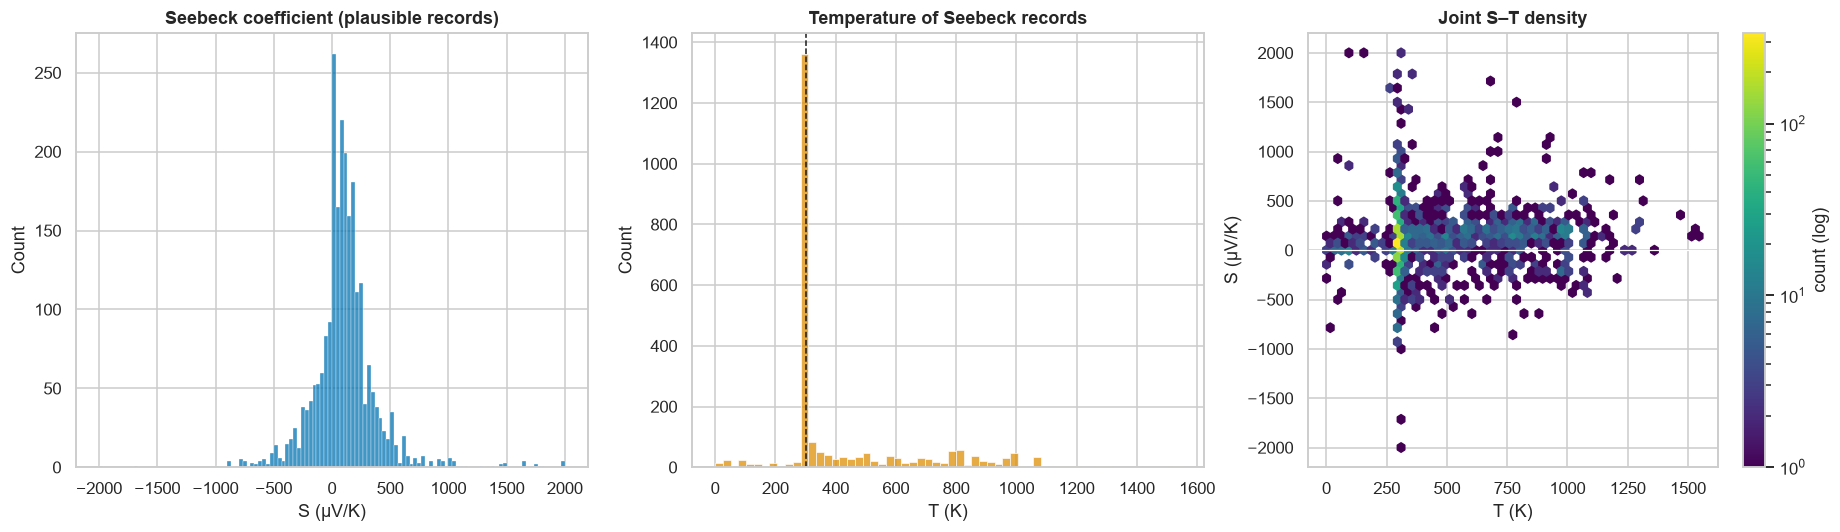

In [29]:
df_cde_S = pd.DataFrame()
if df_cde is not None:
    df_cde_S = df_cde[df_cde["property"] == "seebeck"].dropna(subset=["S_uVK"]).copy()
    df_cde_S["implausible"] = df_cde_S["S_uVK"].abs() > CONFIG["S_plausible_max_uVK"]
    sign = np.sign(df_cde_S["S_uVK"]).map({1.0: "positive (p)", -1.0: "negative (n)", 0.0: "zero"})
    print(f"Seebeck records with numeric value: {len(df_cde_S)}")
    print(f"Implausible (|S| > {CONFIG['S_plausible_max_uVK']:.0f} µV/K): {df_cde_S['implausible'].mean():.2%}")
    print(f"With temperature: {df_cde_S['T_K'].notna().mean():.1%}")
    display(sign.value_counts(normalize=True).rename("fraction").to_frame().T)
    SUMMARY["CDE: Seebeck records with temperature"] = f"{df_cde_S['T_K'].notna().mean():.1%}"

    clean = df_cde_S[~df_cde_S["implausible"]]
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    sns.histplot(clean["S_uVK"], bins=120, ax=axes[0])
    axes[0].set(xlabel="S (µV/K)", title="Seebeck coefficient (plausible records)")
    sns.histplot(clean["T_K"].dropna(), bins=60, ax=axes[1], color="C1")
    axes[1].axvline(CONFIG["T_ref"], c="k", ls="--", lw=1)
    axes[1].set(xlabel="T (K)", title="Temperature of Seebeck records")
    st = clean.dropna(subset=["T_K"])
    st = st[(st["T_K"] > 0) & (st["T_K"] < 2000)]
    if len(st):
        hb = axes[2].hexbin(st["T_K"], st["S_uVK"], gridsize=50, bins="log", cmap="viridis", mincnt=1)
        fig.colorbar(hb, ax=axes[2], label="count (log)")
    axes[2].axhline(0, c="w", lw=0.8)
    axes[2].set(xlabel="T (K)", ylabel="S (µV/K)", title="Joint S–T density")
    fig.tight_layout()
    save_fig(fig, "03_cde_seebeck")
    plt.show()

### 3.5 Compound-name parsability and composition profile
Assesses how many extracted compound names can be normalised to a valid chemical formula. Names containing variable stoichiometry (*x*, *δ*), dopant notation or free text are handled by the cleaning routine below, which is shared with Section 4.

Seebeck records with a parsable formula: 57.9%
Unique parsed formulas: 830


**Examples of unparsable names**

['β-Zn4Sb3', 'Fe2O3 thin films', 'ZnSb thin film', 'single-crystal SrTiO3', '10 wt % TiB2 incorporated PbSe', 'bulk K1.33Mn8O16', 'un-doped SnSe', '0.5 wt. % MWCNT', 'doped GeSi alloys', 'Cu1−xPtxFeO2 sample', 'S 3 #', 'doped n-type PbTe', 'SS bulk', 'Bi1.6Pb0.4Ba2Co2Oy', 'La2NiO4+δ']


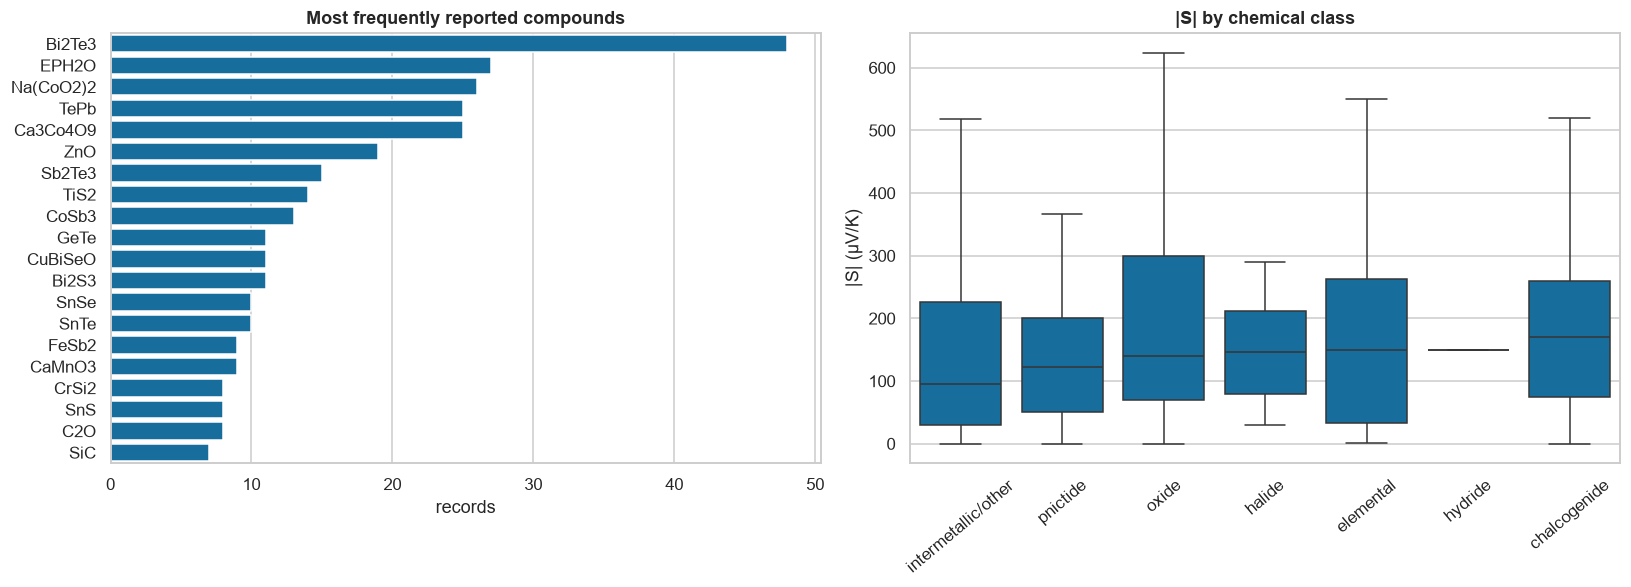

In [30]:
SUBSCRIPTS = str.maketrans("₀₁₂₃₄₅₆₇₈₉", "0123456789")


@lru_cache(maxsize=None)
def clean_formula(raw):
    if not isinstance(raw, str):
        return None
    s = raw.translate(SUBSCRIPTS).replace("−", "-").replace("–", "-").strip()
    s = re.split(r"[:;,/]|\s[-+]\s|\bdoped\b|\bwith\b|\bbased\b", s)[0]
    s = re.sub(r"\s+", "", s)
    s = s.strip("()[]{}'\"")
    if not s or re.search(r"[xzδ]|(?<!D)y", s) or not re.match(r"^[A-Z]", s):
        return None
    try:
        comp = Composition(s)
    except Exception:
        return None
    if len(comp) == 0 or any(v <= 0 for v in comp.values()):
        return None
    if any(not getattr(el, "Z", None) for el in comp.elements):
        return None
    return comp.reduced_formula


if len(df_cde_S):
    df_cde_S["reduced_formula"] = df_cde_S["name"].map(clean_formula)
    parse_rate = df_cde_S["reduced_formula"].notna().mean()
    print(f"Seebeck records with a parsable formula: {parse_rate:.1%}")
    print(f"Unique parsed formulas: {df_cde_S['reduced_formula'].nunique()}")
    SUMMARY["CDE: formula parse rate (Seebeck)"] = f"{parse_rate:.1%}"

    unparsed = df_cde_S.loc[df_cde_S["reduced_formula"].isna(), "name"]
    header("Examples of unparsable names")
    print(unparsed.sample(min(15, len(unparsed)), random_state=CONFIG["random_state"]).tolist())

    feats = pd.DataFrame([composition_features(f) for f in df_cde_S["reduced_formula"]], index=df_cde_S.index)
    df_cde_S = df_cde_S.join(feats[["chemsys", "n_elements", "chem_class"]])

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    top = df_cde_S["reduced_formula"].value_counts().head(20)
    sns.barplot(x=top.values, y=top.index, ax=axes[0], color="C0")
    axes[0].set(xlabel="records", ylabel="", title="Most frequently reported compounds")
    cls = df_cde_S.dropna(subset=["chem_class"])
    cls = cls[~cls["implausible"]]
    order = cls.groupby("chem_class")["S_uVK"].apply(lambda s: s.abs().median()).sort_values().index
    sns.boxplot(data=cls.assign(absS=cls["S_uVK"].abs()), x="chem_class", y="absS", order=order,
                ax=axes[1], showfliers=False)
    axes[1].tick_params(axis="x", rotation=40)
    axes[1].set(ylabel="|S| (µV/K)", xlabel="", title="|S| by chemical class")
    fig.tight_layout()
    save_fig(fig, "03_cde_compounds")
    plt.show()

### 3.6 Publication metadata and duplicate records
Temporal distribution of source publications, records per DOI, and the rate of exact duplicates (same compound, value, temperature and DOI), which would otherwise inflate effective sample size in model training.

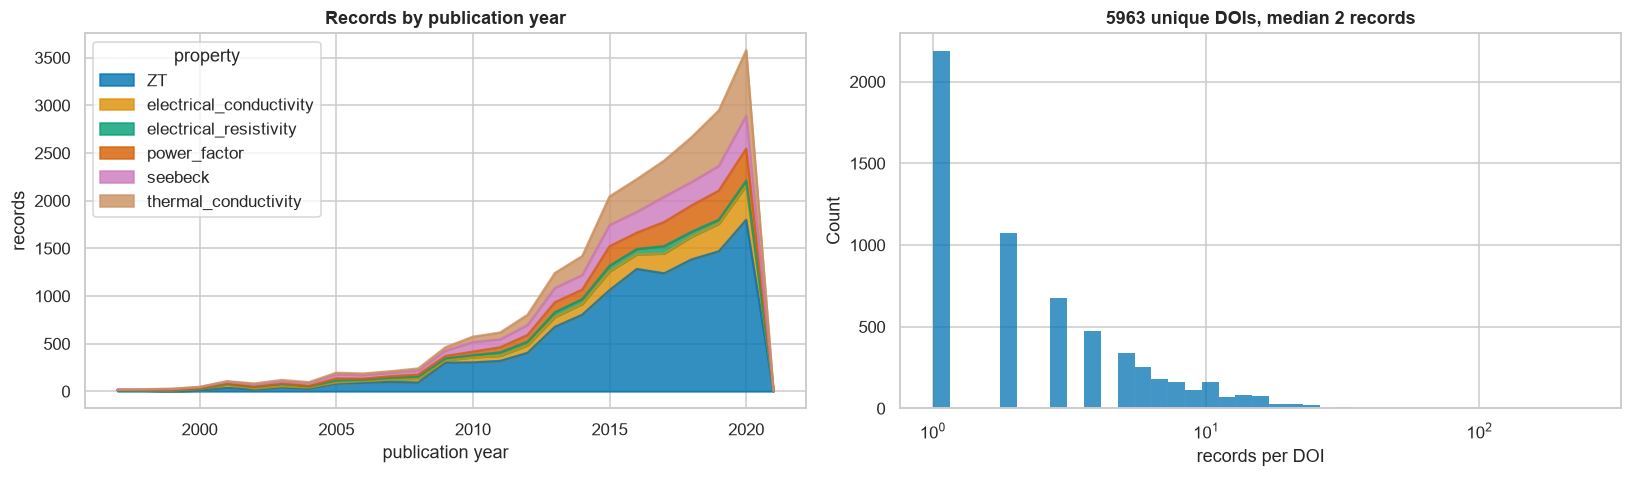

Exact duplicate Seebeck records: 2.42%


In [31]:
if df_cde is not None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    if "year" in df_cde and df_cde["year"].notna().any():
        yr = df_cde.dropna(subset=["year"]).groupby(["year", "property"]).size().unstack(fill_value=0)
        yr[[c for c in yr.columns if c in prop_counts.head(6).index]].plot(kind="area", stacked=True, ax=axes[0], alpha=0.8)
        axes[0].set(xlabel="publication year", ylabel="records", title="Records by publication year")
    if df_cde["doi"].notna().any():
        per_doi = df_cde.groupby("doi").size()
        sns.histplot(per_doi, bins=np.logspace(0, np.log10(per_doi.max() + 1), 40), ax=axes[1])
        axes[1].set(xscale="log", xlabel="records per DOI", title=f"{per_doi.size} unique DOIs, median {per_doi.median():.0f} records")
        SUMMARY["CDE: unique DOIs"] = per_doi.size
    fig.tight_layout()
    save_fig(fig, "03_cde_publications")
    plt.show()

    if len(df_cde_S):
        dup_keys = ["name", "S_uVK", "T_K", "doi"]
        dup_rate = df_cde_S.duplicated(subset=[k for k in dup_keys if k in df_cde_S]).mean()
        print(f"Exact duplicate Seebeck records: {dup_rate:.2%}")
        SUMMARY["CDE: duplicate Seebeck records"] = f"{dup_rate:.2%}"

## 4. DFT–Experiment Composition Matching

### 4.1 Matching strategy
Experimental compositions are matched to DFT entries at three levels of stringency:

| Level | Criterion | Interpretation |
|---|---|---|
| `exact` | identical reduced formula | direct comparison is meaningful |
| `near` | same chemical system and atomic-fraction L1 distance/2 ≤ `composition_tolerance` | lightly doped or off-stoichiometric variant of a DFT compound |
| `chemsys` | same set of elements only | same chemical family; stoichiometry differs |

For teMatDb both the full composition and the base-material field are tried; the most stringent successful level is retained.

In [32]:
def build_dft_index(df):
    index = {}
    for rf in df["reduced_formula"].dropna().unique():
        comp = Composition(rf)
        index.setdefault(comp.chemical_system, []).append((rf, comp.fractional_composition.get_el_amt_dict()))
    return index


DFT_INDEX = build_dft_index(df_dft)
DFT_FORMULAS = set(df_dft["reduced_formula"].dropna())
LEVEL_RANK = {"exact": 0, "near": 1, "chemsys": 2, "none": 3}


@lru_cache(maxsize=None)
def match_to_dft(rf, tol=CONFIG["composition_tolerance"]):
    if not rf:
        return ("none", None, np.nan)
    if rf in DFT_FORMULAS:
        return ("exact", rf, 0.0)
    try:
        comp = Composition(rf)
    except Exception:
        return ("none", None, np.nan)
    candidates = DFT_INDEX.get(comp.chemical_system, [])
    if not candidates:
        return ("none", None, np.nan)
    frac = comp.fractional_composition.get_el_amt_dict()
    dists = [(0.5 * sum(abs(frac.get(e, 0) - f.get(e, 0)) for e in set(frac) | set(f)), cand) for cand, f in candidates]
    d, best = min(dists)
    return ("near" if d <= tol else "chemsys", best, d)


def best_match(formulas):
    results = [match_to_dft(f) for f in formulas if f]
    return min(results, key=lambda r: LEVEL_RANK[r[0]]) if results else ("none", None, np.nan)

### 4.2 Experimental reference tables
Builds one row per experimental observation at the reference temperature: for teMatDb, $S(T_{ref})$ per sample; for ChemDataExtractor, plausible Seebeck records within ±`T_window` of `T_ref`.

In [33]:
exp_frames = []
if len(df_curves):
    t = df_curves.dropna(subset=["S_ref"]).copy()
    cols = [c for c in [comp_col, basemat_col] if c in t]
    t["formula_candidates"] = t[cols].apply(lambda r: tuple(clean_formula(str(v)) for v in r if pd.notna(v)), axis=1) if cols else [()] * len(t)
    t["match"] = t["formula_candidates"].map(best_match)
    t["label"] = t[cols[0]].astype(str) if cols else t["sample_id"]
    exp_frames.append(pd.DataFrame({"dataset": "teMatDb", "label": t["label"], "S_exp": t["S_ref"],
                                    "match_level": t["match"].map(lambda m: m[0]),
                                    "dft_formula": t["match"].map(lambda m: m[1]),
                                    "distance": t["match"].map(lambda m: m[2])}))
if len(df_cde_S):
    c = df_cde_S[(~df_cde_S["implausible"]) & ((df_cde_S["T_K"] - CONFIG["T_ref"]).abs() <= CONFIG["T_window"])].copy()
    c["match"] = c["reduced_formula"].map(lambda f: match_to_dft(f) if f else ("none", None, np.nan))
    exp_frames.append(pd.DataFrame({"dataset": "ChemDataExtractor", "label": c["reduced_formula"].fillna(c["name"]),
                                    "S_exp": c["S_uVK"], "match_level": c["match"].map(lambda m: m[0]),
                                    "dft_formula": c["match"].map(lambda m: m[1]),
                                    "distance": c["match"].map(lambda m: m[2])}))

df_exp = pd.concat(exp_frames, ignore_index=True) if exp_frames else pd.DataFrame()
if len(df_exp):
    df_exp["carrier"] = np.where(df_exp["S_exp"] >= 0, "p", "n")
    print(f"Experimental observations at {CONFIG['T_ref']:.0f} ± {CONFIG['T_window']:.0f} K: {len(df_exp)}")
    display(df_exp.groupby("dataset").size().rename("observations").to_frame().T)

Experimental observations at 300 ± 25 K: 1667


dataset,ChemDataExtractor,teMatDb
observations,1442,225


### 4.3 Overlap statistics
Counts of observations and unique DFT formulas at each matching level. The cumulative counts indicate whether a database-scale matched benchmark is feasible or whether the comparison should be restricted to a curated set of case studies.

observations  unique_dft_formulas  fraction_of_dataset
dataset           match_level                                                        
teMatDb           exact                 101                   10               0.4489
                  near                    0                    0                    0
                  chemsys                 9                    9                 0.04
                  none                  115                    0               0.5111
ChemDataExtractor exact                 130                   46              0.09015
                  near                   19                    7              0.01318
                  chemsys                92                   38               0.0638
                  none                 1201                    0               0.8329

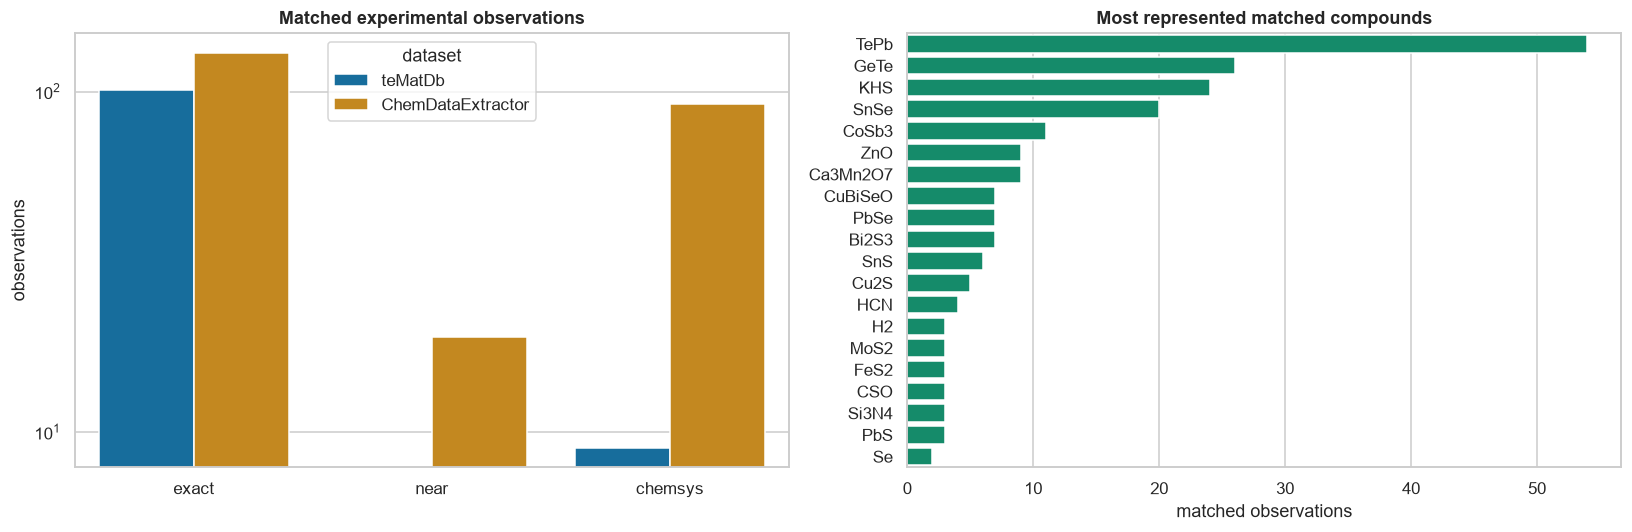

In [34]:
if len(df_exp):
    levels = ["exact", "near", "chemsys", "none"]
    overlap = (df_exp.groupby(["dataset", "match_level"])
               .agg(observations=("S_exp", "size"), unique_dft_formulas=("dft_formula", "nunique"))
               .reindex(pd.MultiIndex.from_product([df_exp["dataset"].unique(), levels]), fill_value=0))
    overlap.index.names = ["dataset", "match_level"]
    overlap["fraction_of_dataset"] = overlap["observations"] / overlap.groupby(level=0)["observations"].transform("sum")
    display(overlap)
    for ds in df_exp["dataset"].unique():
        o = overlap.loc[ds]
        SUMMARY[f"Overlap {ds}: exact / near / chemsys (observations)"] = f"{o.loc['exact','observations']} / {o.loc['near','observations']} / {o.loc['chemsys','observations']}"
        SUMMARY[f"Overlap {ds}: unique DFT formulas (exact+near)"] = int(df_exp[(df_exp["dataset"] == ds) & df_exp["match_level"].isin(["exact", "near"])]["dft_formula"].nunique())

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ov = overlap.reset_index()
    sns.barplot(data=ov[ov["match_level"] != "none"], x="match_level", y="observations", hue="dataset", ax=axes[0])
    axes[0].set(yscale="log", title="Matched experimental observations", xlabel="")
    matched = df_exp[df_exp["match_level"].isin(["exact", "near"])]
    top = matched["dft_formula"].value_counts().head(20)
    sns.barplot(x=top.values, y=top.index, ax=axes[1], color="C2")
    axes[1].set(xlabel="matched observations", ylabel="", title="Most represented matched compounds")
    fig.tight_layout()
    save_fig(fig, "04_overlap")
    plt.show()

### 4.4 DFT versus experiment Seebeck parity
For exact and near matches, the experimental $S(T_{ref})$ is compared with the DFT Seebeck coefficient of the same carrier type (median over polymorphs, with the polymorph range as an error bar). Because DFT values are fixed at 10¹⁸ cm⁻³ whereas practical thermoelectrics are typically doped to 10¹⁹–10²⁰ cm⁻³, experimental |S| is expected to lie below the DFT value; the fraction of such cases is reported.

,dataset,match_level,n,spearman_rho,median_log10(exp/dft),fraction |S_exp| < S_dft
0,ChemDataExtractor,exact,130,-0.09113,-0.3495,0.8077
1,ChemDataExtractor,near,19,0.4121,-0.2345,0.8947
2,teMatDb,exact,101,-0.1341,-0.5257,1


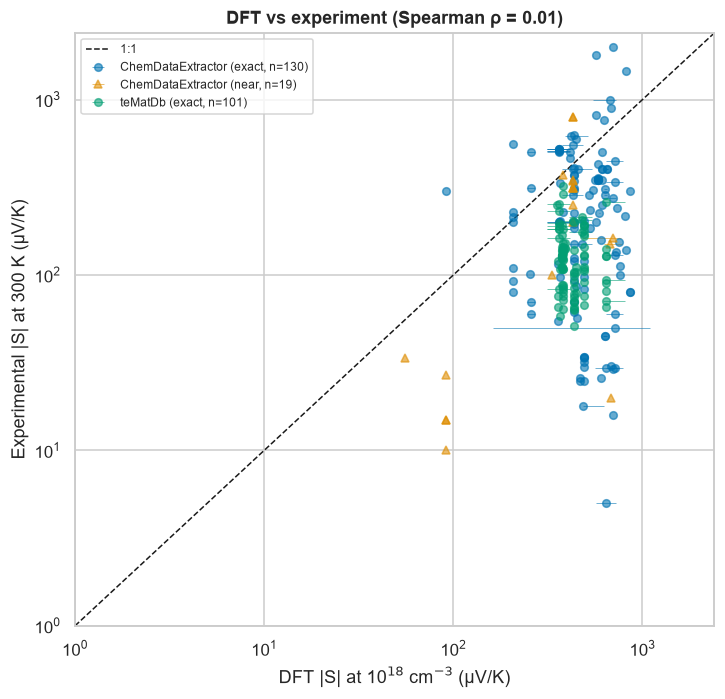

In [35]:
df_parity = pd.DataFrame()
if len(df_exp):
    dft_agg = df_dft.groupby("reduced_formula").agg(
        S_dft_n=("abs_s_n", "median"), S_dft_n_lo=("abs_s_n", "min"), S_dft_n_hi=("abs_s_n", "max"),
        S_dft_p=("abs_s_p", "median"), S_dft_p_lo=("abs_s_p", "min"), S_dft_p_hi=("abs_s_p", "max"),
        m_S_n=("m_S_n", "median"), m_S_p=("m_S_p", "median"), m_c_n=("m_n", "median"), m_c_p=("m_p", "median"))
    df_parity = df_exp[df_exp["match_level"].isin(["exact", "near"])].join(dft_agg, on="dft_formula")
    pick = lambda d, a, b: np.where(d["carrier"] == "p", d[a], d[b])
    df_parity["S_dft"] = pick(df_parity, "S_dft_p", "S_dft_n")
    df_parity["S_dft_lo"] = pick(df_parity, "S_dft_p_lo", "S_dft_n_lo")
    df_parity["S_dft_hi"] = pick(df_parity, "S_dft_p_hi", "S_dft_n_hi")
    df_parity["m_S_dft"] = pick(df_parity, "m_S_p", "m_S_n")
    df_parity["abs_S_exp"] = df_parity["S_exp"].abs()
    df_parity = df_parity.dropna(subset=["S_dft"])
    df_parity = df_parity[(df_parity["abs_S_exp"] > 0) & (df_parity["S_dft"] > 0)]

if len(df_parity):
    rows = []
    for (ds, lvl), g in df_parity.groupby(["dataset", "match_level"]):
        rows.append({"dataset": ds, "match_level": lvl, "n": len(g),
                     "spearman_rho": stats.spearmanr(g["abs_S_exp"], g["S_dft"]).statistic if len(g) > 2 else np.nan,
                     "median_log10(exp/dft)": np.log10(g["abs_S_exp"] / g["S_dft"]).median(),
                     "fraction |S_exp| < S_dft": (g["abs_S_exp"] < g["S_dft"]).mean()})
    parity_stats = pd.DataFrame(rows)
    display(parity_stats)
    rho_all = stats.spearmanr(df_parity["abs_S_exp"], df_parity["S_dft"]).statistic
    SUMMARY["Parity: matched observations"] = len(df_parity)
    SUMMARY["Parity: Spearman |S_exp| vs S_DFT"] = f"{rho_all:.2f}"
    SUMMARY["Parity: fraction |S_exp| < S_DFT(1e18)"] = f"{(df_parity['abs_S_exp'] < df_parity['S_dft']).mean():.1%}"

    fig, ax = plt.subplots(figsize=(7.5, 7))
    markers = {"exact": "o", "near": "^"}
    for (ds, lvl), g in df_parity.groupby(["dataset", "match_level"]):
        ax.errorbar(g["S_dft"], g["abs_S_exp"],
                    xerr=[g["S_dft"] - g["S_dft_lo"], g["S_dft_hi"] - g["S_dft"]],
                    fmt=markers.get(lvl, "o"), ms=5, alpha=0.6, elinewidth=0.6, label=f"{ds} ({lvl}, n={len(g)})")
    lim = [max(1, min(df_parity["S_dft_lo"].min(), df_parity["abs_S_exp"].min()) * 0.8),
           max(df_parity["S_dft_hi"].max(), df_parity["abs_S_exp"].max()) * 1.2]
    ax.plot(lim, lim, "k--", lw=1, label="1:1")
    ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="DFT |S| at 10$^{18}$ cm$^{-3}$ (µV/K)",
           ylabel=f"Experimental |S| at {CONFIG['T_ref']:.0f} K (µV/K)",
           title=f"DFT vs experiment (Spearman ρ = {rho_all:.2f})")
    ax.legend(fontsize=8)
    save_fig(fig, "04_parity_dft_vs_exp")
    plt.show()

### 4.5 SPB-implied carrier concentration
Using the DFT Seebeck mass $m_S^*$ of the matched compound, the SPB model is inverted to find the carrier concentration that reproduces each experimental |S|. This provides a physically grounded estimate of the missing carrier-concentration variable and tests its plausibility: values concentrated in 10¹⁸–10²¹ cm⁻³ support the SPB/DFT combination as a surrogate for unreported Hall data.

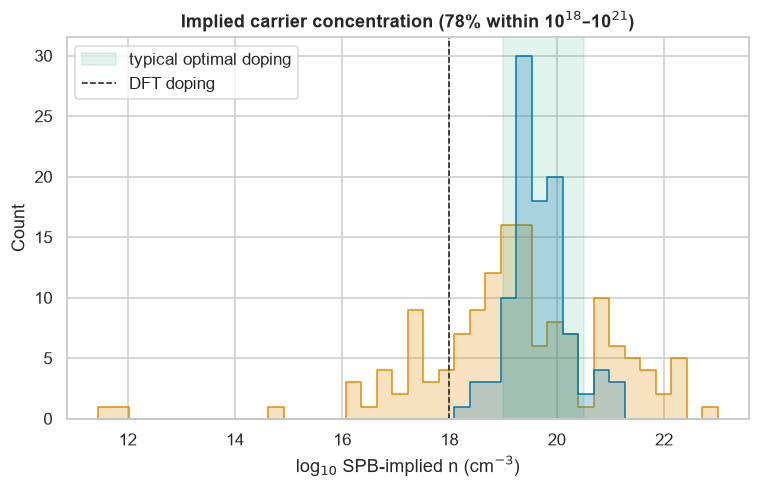

**Matched compounds with the most experimental observations**

,,observations,median_S_exp,S_dft,m_S_dft,median_n_implied
dft_formula,carrier,,,,,
TePb,p,32,112.1,435,0.886,6.002e+19
GeTe,p,24,107.2,492,1.38,1.251e+20
TePb,n,22,-127.6,379,0.572,2.418e+19
KHS,n,18,-128.2,374,0.55,2.253e+19
SnSe,p,16,215.6,364,0.5473,6.888e+18
Ca3Mn2O7,n,9,-312,429,0.8455,3.973e+18
CoSb3,p,8,155,207,0.1425,1.095e+18
CuBiSeO,p,7,353,583,2.795,1.467e+19
KHS,p,6,108.8,640,4.345,7.279e+20


In [36]:
if len(df_parity):
    df_parity["n_implied_cm3"] = spb.carrier_conc(df_parity["abs_S_exp"].values, df_parity["m_S_dft"].values, CONFIG["T_ref"])
    log_n = np.log10(df_parity["n_implied_cm3"].replace([np.inf, -np.inf], np.nan)).dropna()
    in_range = ((log_n >= 18) & (log_n <= 21)).mean()
    SUMMARY["SPB-implied n: median (cm^-3)"] = f"{10 ** log_n.median():.2e}"
    SUMMARY["SPB-implied n: fraction in 1e18-1e21 cm^-3"] = f"{in_range:.1%}"

    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.histplot(data=df_parity.assign(log_n=np.log10(df_parity["n_implied_cm3"])), x="log_n", hue="dataset",
                 bins=40, ax=ax, element="step")
    ax.axvspan(19, 20.5, color="C2", alpha=0.12, label="typical optimal doping")
    ax.axvline(np.log10(CONFIG["dft_doping_cm3"]), c="k", ls="--", lw=1, label="DFT doping")
    ax.set(xlabel="log$_{10}$ SPB-implied n (cm$^{-3}$)", title=f"Implied carrier concentration ({in_range:.0%} within 10$^{{18}}$–10$^{{21}}$)")
    ax.legend()
    save_fig(fig, "04_implied_carrier_concentration")
    plt.show()

    header("Matched compounds with the most experimental observations")
    display(df_parity.groupby(["dft_formula", "carrier"])
            .agg(observations=("S_exp", "size"), median_S_exp=("S_exp", "median"),
                 S_dft=("S_dft", "first"), m_S_dft=("m_S_dft", "first"),
                 median_n_implied=("n_implied_cm3", "median"))
            .sort_values("observations", ascending=False).head(20))

## 5. Summary

### 5.1 Key metrics
All quantitative results collected during the run.

In [37]:
summary_df = pd.DataFrame({"metric": list(SUMMARY.keys()), "value": [str(v) for v in SUMMARY.values()]})
display(summary_df.style.hide(axis="index").set_properties(**{"text-align": "left"}))

metric,value
"DFT: single-point (300 K, 1e18 cm^-3)",True
DFT: entries,8924
DFT: unique reduced formulas,7380
DFT: SPB(m_c) vs BoltzTraP Spearman (n / p),0.86 / 0.49
DFT: SPB(m_c) MdAPE % (n / p),10.9 / 15.6
teMatDb: carrier concentration available,False
teMatDb: samples with S(T),272
teMatDb: Seebeck points,56641
teMatDb: curves with >= 5 points,272
teMatDb: curves with interior |S| peak (bipolar),32.7%


### 5.2 Dataset readiness for Seebeck modelling

In [38]:
readiness = pd.DataFrame([
    {"dataset": "BoltzTraP (matminer)", "records": SUMMARY.get("DFT: entries"),
     "T-dependence": "No (300 K only)", "carrier concentration": "Fixed (1e18 cm^-3)",
     "effective mass": "Yes (conductivity)", "role": "SPB benchmark, descriptor source"},
    {"dataset": "teMatDb272", "records": SUMMARY.get("teMatDb: samples with S(T)"),
     "T-dependence": "Yes (full curves)",
     "carrier concentration": "Yes" if SUMMARY.get("teMatDb: carrier concentration available") else "No",
     "effective mass": "No", "role": "High-quality experimental validation"},
    {"dataset": "ChemDataExtractor", "records": SUMMARY.get("CDE: Seebeck records"),
     "T-dependence": f"Partial ({SUMMARY.get('CDE: Seebeck records with temperature', 'n/a')} with T)",
     "carrier concentration": "Yes" if SUMMARY.get("CDE: carrier concentration available") else "No",
     "effective mass": "No", "role": "Large-scale, noisy experimental coverage"},
])
display(readiness.style.hide(axis="index"))

dataset,records,T-dependence,carrier concentration,effective mass,role
BoltzTraP (matminer),8924,No (300 K only),Fixed (1e18 cm^-3),Yes (conductivity),"SPB benchmark, descriptor source"
teMatDb272,272,Yes (full curves),No,No,High-quality experimental validation
ChemDataExtractor,2484,Partial (100.0% with T),No,No,"Large-scale, noisy experimental coverage"


### 5.3 Interpretation guide

- **Single-point DFT data.** The matminer slice fixes $T$ and $n$; any symbolic-regression model trained on it cannot learn the $S(n,T)$ dependence. The full Ricci et al. grid is available from Dryad (doi:10.5061/dryad.gn001) and is required for doping- and temperature-resolved SPB residuals.
- **SPB benchmark (§1.9–1.10).** Systematic under-prediction by SPB with the conductivity mass, and a broad complexity-factor distribution, quantify band-structure complexity that a learned model must capture beyond SPB. Features correlated with $N_V^*K^*$ are natural candidate descriptors.
- **Experimental curves (§2).** The fraction of curves with bipolar peaks defines the temperature range over which a single-band model is valid; curves should be truncated below `T_at_S_max` before SPB fitting.
- **Overlap (§4.3).** If exact and near matches amount to a small number of well-studied systems, a curated case-study validation set is more appropriate than an automated database-scale join.
- **Parity and implied n (§4.4–4.5).** A consistent offset below the 1:1 line with implied carrier concentrations in 10¹⁹–10²⁰ cm⁻³ indicates that the DFT–experiment discrepancy is dominated by doping level rather than by band-structure error; scattered implied values indicate matching or extraction noise.

### 5.4 Limitations
- teMatDb and ChemDataExtractor schemas are detected automatically; verify the column mapping printed in §2.3 and §3.2 and use `COLUMN_OVERRIDES` if necessary.
- The SPB model assumes a single parabolic band and energy-independent scattering exponent; results for bipolar or multi-band systems are indicative only.
- Composition matching ignores polymorphism and microstructure; polymorph spread (§1.11) bounds the achievable agreement.
- Seebeck unit normalisation for text-mined data relies on unit strings and magnitude heuristics; residual unit errors are partly captured by the plausibility filter.

## 6. Export
Saves all derived tables (CSV) to `outputs/tables`, figures (PNG) to `outputs/figures`, and packages the output directory as a ZIP archive. In Colab the archive is offered for download.

In [39]:
export_tables = {
    "dft_processed": df_dft.drop(columns=[c for c in ["structure"] if c in df_dft]),
    "dft_spb_benchmark": spb_bench.reset_index(),
    "tematdb_seebeck_points": df_tep,
    "tematdb_curve_features": df_curves,
    "cde_seebeck_records": df_cde_S,
    "experimental_matches": df_exp,
    "dft_vs_experiment_parity": df_parity,
    "summary_metrics": summary_df,
}
for name, table in export_tables.items():
    save_table(table, name)

archive = Path(str(CONFIG["output_dir"]) + ".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in CONFIG["output_dir"].rglob("*"):
        if path.is_file():
            zf.write(path, path.relative_to(CONFIG["output_dir"].parent))

saved = sorted(p.relative_to(CONFIG["output_dir"]).as_posix() for p in CONFIG["output_dir"].rglob("*") if p.is_file())
print(f"{len(saved)} files written to {CONFIG['output_dir']}")
print(f"Archive: {archive} ({archive.stat().st_size / 1e6:.1f} MB)")

if IN_COLAB:
    from google.colab import files
    files.download(str(archive))

25 files written to C:\Users\Ekta Jain\Downloads\nb_run\repos\seebeck-spb-symbolic-regression\data_audits\outputs
Archive: C:\Users\Ekta Jain\Downloads\nb_run\repos\seebeck-spb-symbolic-regression\data_audits\outputs.zip (5.4 MB)


## References
1. Ricci, F. *et al.* An ab initio electronic transport database for inorganic materials. *Sci. Data* **4**, 170085 (2017). doi:10.1038/sdata.2017.85
2. Ryu, B. *et al.* teMatDb: a high-quality thermoelectric material database (2025). github.com/byungkiryu/teMatDb
3. Sierepeklis, O. & Cole, J. M. A thermoelectric materials database auto-generated from the scientific literature using ChemDataExtractor. *Sci. Data* **9**, 648 (2022). doi:10.1038/s41597-022-01752-1
4. Gibbs, Z. M. *et al.* Effective mass and Fermi surface complexity factor from ab initio band structure calculations. *npj Comput. Mater.* **3**, 8 (2017).
5. May, A. F. & Snyder, G. J. Introduction to modeling thermoelectric transport at high temperatures. In *Materials, Preparation, and Characterization in Thermoelectrics* (CRC Press, 2012).
6. Goldsmid, H. J. & Sharp, J. W. Estimation of the thermal band gap of a semiconductor from Seebeck measurements. *J. Electron. Mater.* **28**, 869–872 (1999).
7. Ward, L. *et al.* Matminer: an open source toolkit for materials data mining. *Comput. Mater. Sci.* **152**, 60–69 (2018).